# DisasterWatch SDGs 13: Klasifikasi Risiko **Korban Jiwa** pada Laporan Bencana Indonesia

**Proyek**: DisasterWatch — Sistem Prediksi dan Pemetaan Risiko Bencana Indonesia
**Tahap**: Modeling & Evaluasi Klasifikasi (varian target **korban jiwa**; pelengkap `modelling_classification.ipynb` yang memprediksi tingkat dampak)
**Sumber data**: Geoportal Data Bencana Indonesia — BNPB (<https://gis.bnpb.go.id>), 1 Jan 2015 – 27 Okt 2026

---

### Pertanyaan yang dijawab
> *Apakah sebuah laporan bencana akan **memakan korban jiwa** (meninggal atau hilang ≥ 1 orang)?*

Target: **`ada_korban_jiwa`** = 1 jika `meninggal + hilang ≥ 1`, selain itu 0. Kolom `meninggal` dan `hilang` **tidak pernah** dipakai sebagai fitur.

### Dua skenario fitur
| Skenario | Fitur | Situasi pemakaian |
|---|---|---|
| **A — Pra-kejadian** | jenis bencana, lokasi, waktu/musim, riwayat korban jiwa di kab/kota | laporan pertama baru masuk → triase awal tim SAR & medis |
| **B — Dampak awal** | A + jumlah warga menderita, mengungsi, rumah rusak, rumah terendam | data kerusakan & pengungsian sudah masuk, data korban belum terverifikasi (BNPB melapor **bertahap**) |

Jumlah **terluka** sengaja tidak dipakai: korban luka dan korban jiwa berasal dari pendataan korban yang sama, sehingga tidak tersedia lebih awal.

### Kriteria pemilihan model (disesuaikan untuk kelas langka)
Hanya ±4% laporan yang memakan korban jiwa, sehingga model yang selalu menebak "tidak ada korban" sudah ber-*accuracy* ±95.7%.
Karena itu *accuracy* tetap dilaporkan, tetapi peringkat model memakai:

| Kriteria | Ukuran | Arah |
|---|---|---|
| Confusion matrix | **F1 kelas "Ada korban jiwa"** (gabungan precision & recall dari CM) | ↑ |
| Confusion matrix | **Balanced accuracy** (rata-rata recall kedua kelas) | ↑ |
| Gradient descent MSE | MSE sesuai rumus *Learning Performance Analysis* (materi Multi Perceptron) | ↓ |

Pelengkap: PR-AUC & ROC-AUC (tidak bergantung ambang), dan *MSE skill* = 1 − MSE model / MSE tebakan proporsi dasar.

## 1. Setup Lingkungan & Load Data

In [1]:
from pathlib import Path
import time
import copy
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, roc_auc_score, average_precision_score,
                             precision_recall_curve)
from sklearn.inspection import permutation_importance

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

ROOT     = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_DIR = ROOT / 'data' / 'processed'
FIG_DIR  = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

INPUT        = DATA_DIR / 'bnpb_bencana_2015-01-01_2026-10-28.csv'
CLUSTER_FILE = DATA_DIR / 'bnpb_disaster_clusters.csv'
RUN_CV       = True   # set False untuk melewati validasi silang 5-fold (lebih cepat)

print('Input   :', INPUT.relative_to(ROOT))
print('Klaster :', CLUSTER_FILE.relative_to(ROOT), '| ada =', CLUSTER_FILE.exists())

Input   : data/processed/bnpb_bencana_2015-01-01_2026-10-28.csv
Klaster : data/processed/bnpb_disaster_clusters.csv | ada = True


In [2]:
# ── Gaya visual konsisten dengan notebook klasifikasi severity ───────────────
CLASS_LABELS = ['Tidak ada korban jiwa', 'Ada korban jiwa']
CLASS_COLORS = ['#86b6ef', '#0d366b']

MODEL_ORDER  = ['Logistic Regression', 'Decision Tree', 'Random Forest',
                'Gradient Boosting', 'MLP (scikit-learn)', 'MLP Backprop (manual)']
MODEL_COLORS = dict(zip(MODEL_ORDER, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']))
SCENARIOS    = {'A': 'A — Pra-kejadian', 'B': 'B — Dampak awal'}

INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'legend.frameon': False, 'font.size': 10, 'lines.linewidth': 2,
})
CM_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'biru', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches='tight')

In [3]:
USECOLS = ['id_prov', 'id_kab', 'provinsi', 'kabkot', 'kejadian', 'lokasi', 'tahun', 'bulan', 'tanggal',
           'meninggal', 'hilang', 'terluka', 'menderita', 'mengungsi', 'rumah_rusak', 'terendam',
           'geometry_lon', 'geometry_lat', 'lng_prov', 'lat_prov']
df_raw = pd.read_csv(INPUT, usecols=USECOLS, low_memory=False)
print(f'Shape mentah: {df_raw.shape}')

# Bukti bahwa sel kosong pada `meninggal` berarti 0 (bukan data hilang):
m = pd.to_numeric(df_raw.meninggal, errors='coerce')
cek_null = pd.DataFrame({'% kosong': m.isna().groupby(df_raw.tahun).mean().mul(100).round(1),
                         'jumlah nol eksplisit': (m == 0).groupby(df_raw.tahun).sum(),
                         'nilai terkecil terisi': m.groupby(df_raw.tahun).min()})
display(cek_null.T)

Shape mentah: (44290, 20)


tahun,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% kosong,0.0,0.0,0.0,0.0,93.9,0.0,0.0,96.8,97.7,21.9,47.6,95.2
jumlah nol eksplisit,1592.0,2169.0,2748.0,3350.0,108.0,4793.0,6073.0,0.0,0.0,2701.0,1574.0,0.0
nilai terkecil terisi,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0


Pada 2022, 2023, dan 2026 kolom `meninggal` ±95–98% kosong, tetapi **tidak ada satu pun nol eksplisit** dan nilai terkecil yang terisi
adalah 1. Artinya pada tahun-tahun itu BNPB hanya mengisi kolom bila ada korban, sehingga **kosong = 0 korban** (konvensi yang sama dengan
`preprocessing_disaster.ipynb`). Tahun 2019 (94% kosong) polanya serupa meski masih ada sedikit nol eksplisit. Proporsi laporan berkorban
jiwa per tahun di bagian 2 tetap dalam rentang yang sama (2–7%) untuk tahun-tahun "kosong" maupun "terisi", mendukung interpretasi ini.

In [4]:
# ── Pembersihan (konvensi sama dengan notebook preprocessing & severity) ──────
df = df_raw.copy()
IMPACT = ['meninggal', 'hilang', 'terluka', 'menderita', 'mengungsi', 'rumah_rusak', 'terendam']

for c in ['kejadian', 'kabkot', 'provinsi', 'lokasi']:
    df[c] = df[c].astype(str).str.strip().str.upper()
prov_name = df.groupby('id_prov')['provinsi'].agg(lambda s: s.value_counts().index[0])
df['provinsi'] = df['id_prov'].map(prov_name)

df['date'] = pd.to_datetime(dict(year=df.tahun, month=df.bulan, day=df.tanggal), errors='coerce')
n0 = len(df); df = df.dropna(subset=['date', 'kejadian', 'id_kab'])
print(f'Drop tanggal/identitas invalid : {n0 - len(df)}')

for c in IMPACT:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0).clip(lower=0)

dup_mask = df.duplicated(subset=['date', 'id_kab', 'kejadian', 'lokasi'] + IMPACT, keep='first')
df = df[~dup_mask]
print(f'Drop laporan ganda             : {dup_mask.sum()}')
print(f'Shape bersih                   : {df.shape}')

Drop tanggal/identitas invalid : 0
Drop laporan ganda             : 129
Shape bersih                   : (44161, 21)


## 2. Target: Ada Korban Jiwa

In [5]:
df['korban_jiwa']     = df.meninggal + df.hilang
df['ada_korban_jiwa'] = (df.korban_jiwa >= 1).astype(int)

n_pos, n_all = df.ada_korban_jiwa.sum(), len(df)
print(f'Laporan dengan korban jiwa : {n_pos:,} dari {n_all:,} ({n_pos/n_all*100:.2f}%)')
print(f'  ≥ 5 korban jiwa          : {(df.korban_jiwa >= 5).sum():,} ({(df.korban_jiwa >= 5).mean()*100:.2f}%)')
print(f'  ≥ 10 korban jiwa         : {(df.korban_jiwa >= 10).sum():,}')
print(f'Total korban jiwa tercatat : {int(df.korban_jiwa.sum()):,} jiwa')
print(f'Rasio kelas (tidak : ada)  : {(n_all - n_pos) / n_pos:.1f} : 1')

Laporan dengan korban jiwa : 1,906 dari 44,161 (4.32%)
  ≥ 5 korban jiwa          : 248 (0.56%)
  ≥ 10 korban jiwa         : 113
Total korban jiwa tercatat : 13,391 jiwa
Rasio kelas (tidak : ada)  : 22.2 : 1


Target dibuat **biner** karena laporan dengan ≥ 5 korban jiwa hanya ±0.6% (±250 laporan) — terlalu sedikit untuk dipelajari sebagai kelas tersendiri.
Sebaran korban jiwa juga sangat timpang: sebagian kecil kejadian (gempa–tsunami, longsor besar) menyumbang mayoritas total korban.

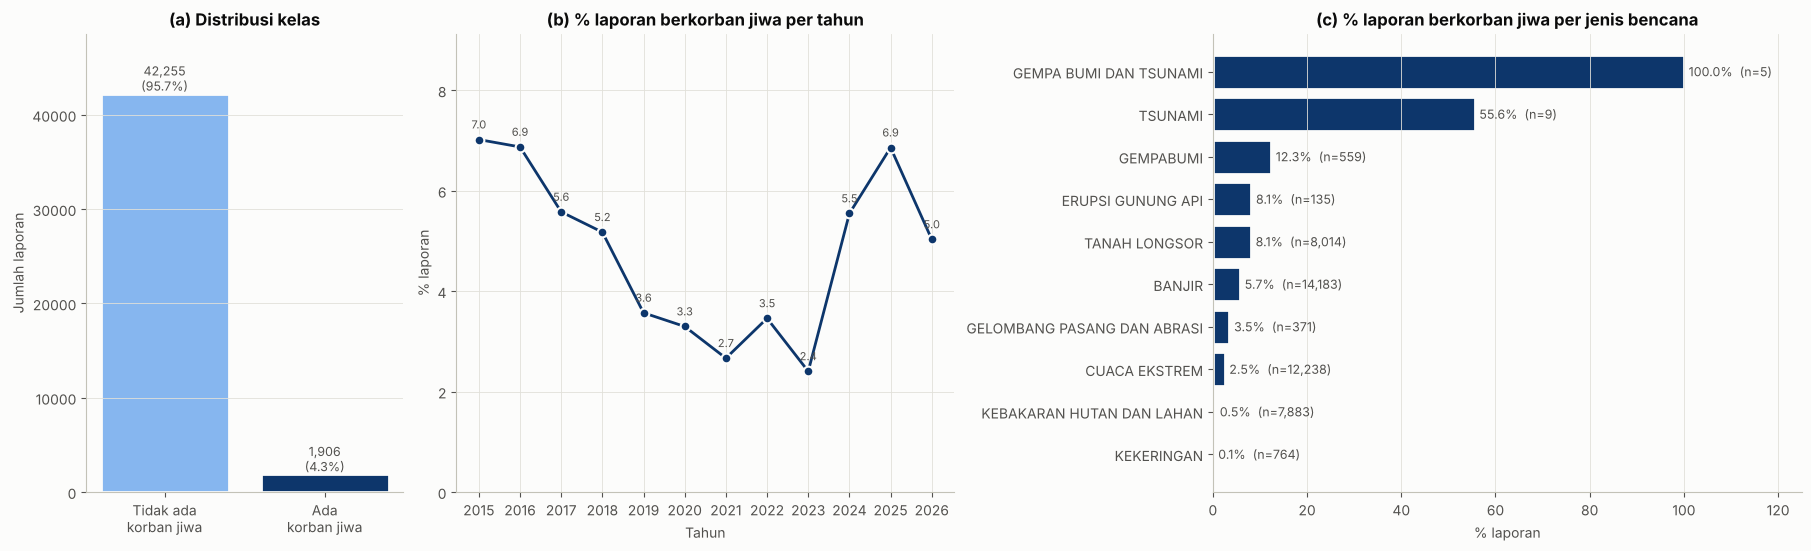

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw={'width_ratios': [0.7, 1.1, 1.3]}, layout='constrained')

ax = axes[0]
cnt = df.ada_korban_jiwa.value_counts().sort_index()
bars = ax.bar(['Tidak ada\nkorban jiwa', 'Ada\nkorban jiwa'], cnt.values, color=CLASS_COLORS, edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, labels=[f'{v:,}\n({v/n_all*100:.1f}%)' for v in cnt.values], fontsize=9, color=INK2)
ax.set(title='(a) Distribusi kelas', ylabel='Jumlah laporan'); ax.set_ylim(0, cnt.max() * 1.15); ax.grid(axis='x', visible=False)

ax = axes[1]
yr = df.groupby(df.date.dt.year).ada_korban_jiwa.mean() * 100
ax.plot(yr.index, yr.values, color=CLASS_COLORS[1], marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
for x, v in yr.items():
    ax.annotate(f'{v:.1f}', (x, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8, color=INK2)
ax.set(title='(b) % laporan berkorban jiwa per tahun', xlabel='Tahun', ylabel='% laporan', ylim=(0, yr.max() * 1.3))
ax.set_xticks(yr.index)

ax = axes[2]
kt = (df.groupby('kejadian').agg(n=('ada_korban_jiwa', 'size'), pct=('ada_korban_jiwa', 'mean'))
        .assign(pct=lambda d: d.pct * 100).sort_values('pct'))
ax.barh(kt.index, kt.pct, color=CLASS_COLORS[1], edgecolor=SURFACE, linewidth=2)
for i, (p, n) in enumerate(zip(kt.pct, kt.n)):
    ax.text(p + 1, i, f'{p:.1f}%  (n={n:,})', va='center', fontsize=9, color=INK2)
ax.set(title='(c) % laporan berkorban jiwa per jenis bencana', xlabel='% laporan', xlim=(0, 125)); ax.grid(axis='y', visible=False)
savefig(fig, 'kj_distribusi_target.png'); plt.show()

**Catatan EDA:**
- Kelas sangat tidak seimbang (±22 : 1). Inilah alasan *accuracy* tidak dipakai untuk memeringkat model.
- Peluang korban jiwa sangat berbeda per jenis: gempabumi, erupsi, dan **tanah longsor** jauh lebih mematikan per laporan dibanding cuaca ekstrem, karhutla, atau kekeringan.
- Proporsi laporan berkorban jiwa berfluktuasi 2.4–7%: turun pada 2019–2023 (saat banyak laporan kecil masuk) dan naik lagi mulai 2024
  (laporan lebih sedikit tetapi lebih besar). Pergeserannya jauh lebih kecil dibanding label severity, tetapi tetap ada, sehingga
  `year` dan `era_2024` tetap dimasukkan sebagai fitur.

## 3. Feature Engineering

Fitur pra-kejadian sama dengan notebook severity, tetapi fitur riwayat kini menghitung **tingkat korban jiwa** pada laporan **sebelumnya**
(tanggal lebih awal) di kab/kota yang sama, dan di kab/kota + jenis bencana yang sama. Penghalusan Bayesian memakai α = 10 karena kejadiannya langka.

| Kelompok | Fitur | Skenario |
|---|---|---|
| Jenis bencana | `kejadian` | A, B |
| Lokasi | `region`, `provinsi`, `lon`, `lat` | A, B |
| Waktu & musim | `month_sin`, `month_cos`, `musim_hujan`, `year`, `era_2024` | A, B |
| Riwayat korban jiwa | `kab_log_n`, `kab_fatal_rate`, `kab_days_since`, `kabtype_log_n`, `kabtype_fatal_rate`, `kabtype_days_since` | A, B |
| Dampak awal (log1p) | `log_menderita`, `log_mengungsi`, `log_rumah_rusak`, `log_terendam` | **B saja** |

In [7]:
def region_from_prov(p):
    p = int(p)
    if 11 <= p <= 21:   return 'Sumatera'
    if 31 <= p <= 36:   return 'Jawa'
    if p == 51:         return 'Bali'
    if p in (52, 53):   return 'Nusa Tenggara'
    if 61 <= p <= 65:   return 'Kalimantan'
    if 71 <= p <= 76:   return 'Sulawesi'
    if p in (81, 82):   return 'Maluku'
    return 'Papua'

df = df.sort_values('date').reset_index(drop=True)
df['region']      = df['id_prov'].apply(region_from_prov)
df['month']       = df.date.dt.month
df['year']        = df.date.dt.year
df['month_sin']   = np.sin(2 * np.pi * df.month / 12)
df['month_cos']   = np.cos(2 * np.pi * df.month / 12)
df['musim_hujan'] = df.month.isin([11, 12, 1, 2, 3]).astype(int)
df['era_2024']    = (df.year >= 2024).astype(int)

df['lon'] = pd.to_numeric(df.geometry_lon, errors='coerce')
df['lat'] = pd.to_numeric(df.geometry_lat, errors='coerce')
df.loc[~df.lon.between(94, 142), 'lon'] = np.nan
df.loc[~df.lat.between(-12, 7),  'lat'] = np.nan
for c, fallback in [('lon', 'lng_prov'), ('lat', 'lat_prov')]:
    df[c] = df[c].fillna(df.groupby('id_kab')[c].transform('mean'))
    df[c] = df[c].fillna(pd.to_numeric(df[fallback], errors='coerce'))
    df[c] = df[c].fillna(df[c].median())

for c in ['menderita', 'mengungsi', 'rumah_rusak', 'terendam']:
    df[f'log_{c}'] = np.log1p(df[c])

def add_history_features(data, keys, prefix, alpha=10):
    # Tingkat korban jiwa dari laporan dengan tanggal LEBIH AWAL pada grup `keys`
    d = data.copy()
    g = (d.groupby(keys + ['date']).agg(_n=('ada_korban_jiwa', 'size'), _s=('ada_korban_jiwa', 'sum'))
           .reset_index().sort_values(keys + ['date']))
    for c in ['_n', '_s']:
        g[c + '_past'] = g.groupby(keys)[c].cumsum() - g[c]
    g['_last'] = g.groupby(keys)['date'].shift(1)
    d = d.merge(g[keys + ['date', '_n_past', '_s_past', '_last']], on=keys + ['date'], how='left')
    prior = d.loc[d.year <= 2017, 'ada_korban_jiwa'].mean()      # prior dari periode awal saja
    d[f'{prefix}_log_n']      = np.log1p(d._n_past)
    d[f'{prefix}_fatal_rate'] = (d._s_past + alpha * prior) / (d._n_past + alpha)
    d[f'{prefix}_days_since'] = np.log1p((d.date - d._last).dt.days.fillna(3650))
    return d.drop(columns=['_n_past', '_s_past', '_last'])

df = add_history_features(df, ['id_kab'], 'kab')
df = add_history_features(df, ['id_kab', 'kejadian'], 'kabtype')

CAT_FEATURES = ['kejadian', 'region', 'provinsi']
NUM_BASE     = ['lon', 'lat', 'month_sin', 'month_cos', 'musim_hujan', 'year', 'era_2024',
                'kab_log_n', 'kab_fatal_rate', 'kab_days_since',
                'kabtype_log_n', 'kabtype_fatal_rate', 'kabtype_days_since']
NUM_IMPACT   = ['log_menderita', 'log_mengungsi', 'log_rumah_rusak', 'log_terendam']
NUM_FEATURES = {'A': NUM_BASE, 'B': NUM_BASE + NUM_IMPACT}
FEATURES     = {s: CAT_FEATURES + NUM_FEATURES[s] for s in SCENARIOS}

assert not set(FEATURES['B']) & {'meninggal', 'hilang', 'korban_jiwa', 'terluka'}, 'kebocoran target!'
y = df['ada_korban_jiwa'].values
print({s: len(f) for s, f in FEATURES.items()}, '| missing:', df[FEATURES['B']].isna().sum().sum())
display(df[NUM_FEATURES['B']].describe().T[['mean', 'std', 'min', 'max']].round(3))

{'A': 16, 'B': 20} | missing: 0


,mean,std,min,max
lon,110.094,7.242,95.306,140.809
lat,-4.328,3.875,-10.726,5.838
month_sin,0.081,0.725,-1.000,1.000
month_cos,0.130,0.671,-1.000,1.000
musim_hujan,0.518,0.500,0.000,1.000
year,2020.883,2.963,2015.000,2026.000
era_2024,0.213,0.410,0.000,1.000
kab_log_n,4.045,1.419,0.000,7.797
kab_fatal_rate,0.049,0.037,0.003,0.311
kab_days_since,2.651,1.628,0.693,8.203


## 4. Pembagian Data

Stratified split 70% *train* / 10% *validation* / 20% *test* — **indeks yang sama** untuk kedua skenario agar perbandingan adil.
*Validation* dipakai untuk (1) memilih iterasi terbaik dari kurva MSE dan (2) memilih **ambang keputusan** (lihat bagian 5).

In [8]:
idx_all = np.arange(len(df))
idx_tmp, idx_test = train_test_split(idx_all, test_size=0.20, stratify=y, random_state=RANDOM_SEED)
idx_train, idx_val = train_test_split(idx_tmp, test_size=0.125, stratify=y[idx_tmp], random_state=RANDOM_SEED)
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

def make_preprocessor(scenario):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES),
        ('num', StandardScaler(), NUM_FEATURES[scenario])])

DATA = {}
for s in SCENARIOS:
    X = df[FEATURES[s]]
    pre = make_preprocessor(s).fit(X.iloc[idx_train])
    DATA[s] = dict(pre=pre, X_test=X.iloc[idx_test],
                   Z_train=pre.transform(X.iloc[idx_train]), Z_val=pre.transform(X.iloc[idx_val]),
                   Z_test=pre.transform(X.iloc[idx_test]))
    print(f"Skenario {s}: {DATA[s]['Z_train'].shape[1]} fitur setelah encoding")

display(pd.DataFrame({'n': [len(y_train), len(y_val), len(y_test)],
                      '% ada korban jiwa': [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100]},
                     index=['train', 'val', 'test']).round(2))

Skenario A: 69 fitur setelah encoding


Skenario B: 73 fitur setelah encoding


,n,% ada korban jiwa
train,30912,4.32
val,4416,4.33
test,8833,4.31


## 5. Teori: MSE, Gradient Descent & Ambang Keputusan

### 5.1 MSE (Learning Performance Analysis — materi Multi Perceptron)
Dengan *k* = 2 unit output (target one-hot: [1, 0] = tidak ada korban, [0, 1] = ada korban):

$$SE_d = (Target_1 - C_1)^2 + (Target_2 - C_2)^2 \qquad SSE = \sum_{d=1}^{f} SE_d \qquad MSE = \frac{SSE}{f}$$

Karena 96% data adalah kelas "tidak ada korban", MSE semua model kecil. Pembanding yang adil adalah **MSE tebakan proporsi dasar**
(selalu memberi peluang 4.3%), lalu dihitung **MSE skill** = 1 − MSE model / MSE dasar (0 = tidak lebih baik dari tebakan, 1 = sempurna).

### 5.2 Backpropagation
Sama dengan materi: sigmoid $y' = y(1-y)$; $dC_j = C_j(1-C_j)(T_j-C_j)$; $dH_i = H_i(1-H_i)\sum_j w_{(i,j)}dC_j$; $w = w + \mu \cdot I \cdot \delta$.

### 5.3 Ambang keputusan (*threshold*)
Model mengeluarkan peluang korban jiwa *p*. Ambang default 0.5 hampir tidak pernah tercapai pada kelas langka, sehingga model
"diam" (selalu memprediksi tidak ada korban). Ambang tiap model dipilih pada data **validation** yang memaksimalkan F1 kelas
"Ada korban jiwa", lalu dipakai apa adanya di data uji. MSE dihitung dari peluang, sehingga **tidak terpengaruh ambang**.

In [9]:
def mse_pdf(y_true, C, k=2):
    # MSE sesuai slide: SE_d = Σ_k (Target_k − C_k)², MSE = SSE / f
    T    = np.eye(k)[np.asarray(y_true)]
    SE_d = ((T - np.asarray(C)) ** 2).sum(axis=1)
    return SE_d.sum() / len(SE_d)

prior_pos = y_train.mean()
MSE_PRIOR = mse_pdf(y_test, np.tile([1 - prior_pos, prior_pos], (len(y_test), 1)))
print(f'Proporsi dasar (train)          : {prior_pos:.4f}')
print(f'MSE tebakan proporsi dasar      : {MSE_PRIOR:.4f}  ← pembanding MSE model')
print(f'Accuracy "selalu tidak ada korban": {(y_test == 0).mean():.4f}  ← pembanding accuracy')

def best_threshold(y_true, score):
    # ambang yang memaksimalkan F1 kelas positif pada data validation
    prec, rec, thr = precision_recall_curve(y_true, score)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i])

Proporsi dasar (train)          : 0.0432
MSE tebakan proporsi dasar      : 0.0825  ← pembanding MSE model
Accuracy "selalu tidak ada korban": 0.9569  ← pembanding accuracy


## 6. Pelatihan 6 Model & Pencatatan Kurva MSE

Model dan cara pencatatan kurva sama dengan notebook severity:

| # | Model | "Iterasi" pada kurva MSE |
|---|---|---|
| 1 | Logistic Regression (SAGA = *stochastic gradient*) | epoch |
| 2 | Decision Tree | kedalaman pohon (tidak iteratif → kurva kompleksitas) |
| 3 | Random Forest | jumlah pohon |
| 4 | Gradient Boosting (HistGradientBoosting) | iterasi boosting |
| 5 | MLP scikit-learn (ReLU, Adam) | epoch |
| 6 | MLP Backpropagation manual (sigmoid, rumus materi) | epoch |

Titik terbaik tiap model = iterasi dengan **MSE validation terendah**.

In [10]:
class BackpropMLP(ClassifierMixin, BaseEstimator):
    # Multi Perceptron + Backpropagation sesuai materi (sigmoid, k output units, L hidden layers)

    def __init__(self, hidden_layers=(32,), mu=0.2, epochs=100, batch_size=64, init_range=0.5, random_state=42):
        self.hidden_layers, self.mu, self.epochs = hidden_layers, mu, epochs
        self.batch_size, self.init_range, self.random_state = batch_size, init_range, random_state

    @staticmethod
    def _sigmoid(x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))

    @staticmethod
    def _bias(A):
        return np.hstack([np.ones((A.shape[0], 1)), A])

    def _forward(self, X):
        acts = [X]
        for W in self.weights_:
            acts.append(self._sigmoid(self._bias(acts[-1]) @ W))
        return acts

    def fit(self, X, y, X_val=None, y_val=None):
        X, y = np.asarray(X, float), np.asarray(y)
        self.classes_ = np.unique(y)
        T = (y[:, None] == self.classes_[None, :]).astype(float)
        rng = np.random.default_rng(self.random_state)
        sizes = [X.shape[1], *self.hidden_layers, len(self.classes_)]
        self.weights_ = [rng.uniform(-self.init_range, self.init_range, (sizes[i] + 1, sizes[i + 1]))
                         for i in range(len(sizes) - 1)]
        self.history_, best_val, best_w = [], np.inf, None
        y_idx = np.searchsorted(self.classes_, y)
        if X_val is not None:
            yv_idx = np.searchsorted(self.classes_, y_val)
            self.history_.append((0, mse_pdf(y_idx, self.predict_proba(X)), mse_pdf(yv_idx, self.predict_proba(X_val))))
        for ep in range(1, self.epochs + 1):
            idx = rng.permutation(len(X))
            for s in range(0, len(X), self.batch_size):
                b = idx[s:s + self.batch_size]
                acts = self._forward(X[b])
                C = acts[-1]
                delta = C * (1 - C) * (T[b] - C)                                  # dC_j
                for L in range(len(self.weights_) - 1, -1, -1):
                    dW = self.mu * self._bias(acts[L]).T @ delta / len(b)          # dw = μ · input · delta
                    if L > 0:
                        H = acts[L]
                        delta = H * (1 - H) * (delta @ self.weights_[L][1:].T)     # dH_i
                    self.weights_[L] += dW                                         # w = w + dw
            if X_val is None:
                continue
            mse_tr, mse_va = mse_pdf(y_idx, self.predict_proba(X)), mse_pdf(yv_idx, self.predict_proba(X_val))
            self.history_.append((ep, mse_tr, mse_va))
            if mse_va < best_val:
                best_val, best_w, self.best_epoch_ = mse_va, [w.copy() for w in self.weights_], ep
        if best_w is not None:
            self.weights_ = best_w
        return self

    def predict_proba(self, X):
        return self._forward(np.asarray(X, float))[-1]

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [11]:
GB_PARAMS  = dict(learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, early_stopping=False, random_state=RANDOM_SEED)
MLP_PARAMS = dict(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=1e-4,
                  batch_size=256, learning_rate_init=1e-3, random_state=RANDOM_SEED)
# μ = 0.5 & 250 epoch: pada kelas langka, μ = 0.2 masih belum konvergen setelah 250 epoch
BP_PARAMS  = dict(hidden_layers=(32,), mu=0.5, epochs=250, batch_size=64, init_range=0.5, random_state=RANDOM_SEED)

def curve_point(model, it, Ztr, Zva):
    return (it, mse_pdf(y_train, model.predict_proba(Ztr)), mse_pdf(y_val, model.predict_proba(Zva)))

def train_all(s):
    Ztr, Zva = DATA[s]['Z_train'], DATA[s]['Z_val']
    res = {}
    def rec(name, model, hist, label, best_it, t0, params):
        res[name] = dict(model=model, history=pd.DataFrame(hist, columns=['iter', 'mse_train', 'mse_val']),
                         iter_label=label, best_iter=best_it, train_time=time.time() - t0, params=params)
        h = res[name]['history']; b = h.loc[h.mse_val.idxmin()]
        print(f'[{s}] {name:24s} | terbaik ({label}) = {best_it:>4} | MSE val = {b.mse_val:.4f} | {res[name]["train_time"]:.1f} s')

    # 1) Logistic Regression — SAGA, 1 fit = 1 epoch
    t0 = time.time()
    lr = LogisticRegression(solver='saga', C=1.0, max_iter=1, tol=1e-12, warm_start=True, random_state=RANDOM_SEED)
    hist = [(0, mse_pdf(y_train, np.full((len(y_train), 2), 0.5)), mse_pdf(y_val, np.full((len(y_val), 2), 0.5)))]
    best = (np.inf, None, 0)
    for ep in range(1, 31):
        lr.fit(Ztr, y_train); hist.append(curve_point(lr, ep, Ztr, Zva))
        if hist[-1][2] < best[0]: best = (hist[-1][2], copy.deepcopy(lr), ep)
    rec('Logistic Regression', best[1], hist, 'epoch', best[2], t0, {'C': 1.0, 'epochs': best[2]})

    # 2) Decision Tree — kurva kompleksitas
    t0 = time.time(); hist, best = [], (np.inf, None, 0)
    for depth in range(1, 21):
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=RANDOM_SEED).fit(Ztr, y_train)
        hist.append(curve_point(dt, depth, Ztr, Zva))
        if hist[-1][2] < best[0]: best = (hist[-1][2], dt, depth)
    rec('Decision Tree', best[1], hist, 'max_depth', best[2], t0, {'max_depth': best[2], 'min_samples_leaf': 20})

    # 3) Random Forest — MSE vs jumlah pohon
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=0, min_samples_leaf=3, max_features='sqrt', warm_start=True, n_jobs=-1, random_state=RANDOM_SEED)
    hist = []
    for n in range(10, 301, 10):
        rf.set_params(n_estimators=n).fit(Ztr, y_train); hist.append(curve_point(rf, n, Ztr, Zva))
    best_n = int(pd.DataFrame(hist).set_index(0)[2].idxmin())
    rf_best = RandomForestClassifier(n_estimators=best_n, min_samples_leaf=3, max_features='sqrt', n_jobs=-1,
                                     random_state=RANDOM_SEED).fit(Ztr, y_train)
    rec('Random Forest', rf_best, hist, 'jumlah pohon', best_n, t0, {'n_estimators': best_n})

    # 4) Gradient Boosting — MSE per iterasi boosting
    t0 = time.time()
    gb = HistGradientBoostingClassifier(max_iter=400, **GB_PARAMS).fit(Ztr, y_train)
    hist = [(i + 1, mse_pdf(y_train, a), mse_pdf(y_val, b))
            for i, (a, b) in enumerate(zip(gb.staged_predict_proba(Ztr), gb.staged_predict_proba(Zva)))]
    best_it = int(pd.DataFrame(hist).set_index(0)[2].idxmin())
    rec('Gradient Boosting', HistGradientBoostingClassifier(max_iter=best_it, **GB_PARAMS).fit(Ztr, y_train),
        hist, 'iterasi boosting', best_it, t0, {'max_iter': best_it})

    # 5) MLP scikit-learn — partial_fit per epoch
    t0 = time.time(); mlp = MLPClassifier(**MLP_PARAMS); hist, best = [], (np.inf, None, 0)
    for ep in range(1, 61):
        mlp.partial_fit(Ztr, y_train, classes=np.array([0, 1])); hist.append(curve_point(mlp, ep, Ztr, Zva))
        if hist[-1][2] < best[0]: best = (hist[-1][2], copy.deepcopy(mlp), ep)
    rec('MLP (scikit-learn)', best[1], hist, 'epoch', best[2], t0, {'epochs': best[2]})

    # 6) MLP Backprop manual
    t0 = time.time(); bp = BackpropMLP(**BP_PARAMS).fit(Ztr, y_train, Zva, y_val)
    rec('MLP Backprop (manual)', bp, bp.history_, 'epoch', bp.best_epoch_, t0, {'epochs': bp.best_epoch_})
    return res

RESULTS = {}
for s in SCENARIOS:
    RESULTS[s] = train_all(s)
    print()

[A] Logistic Regression      | terbaik (epoch) =   30 | MSE val = 0.0777 | 0.8 s


[A] Decision Tree            | terbaik (max_depth) =    5 | MSE val = 0.0784 | 3.7 s


[A] Random Forest            | terbaik (jumlah pohon) =  270 | MSE val = 0.0766 | 19.4 s


[A] Gradient Boosting        | terbaik (iterasi boosting) =   61 | MSE val = 0.0766 | 4.8 s


[A] MLP (scikit-learn)       | terbaik (epoch) =   12 | MSE val = 0.0755 | 6.6 s


[A] MLP Backprop (manual)    | terbaik (epoch) =  157 | MSE val = 0.0771 | 13.6 s



... (2 outputs left out)

[B] Random Forest            | terbaik (jumlah pohon) =  290 | MSE val = 0.0678 | 20.6 s


[B] Gradient Boosting        | terbaik (iterasi boosting) =  200 | MSE val = 0.0642 | 6.3 s


[B] MLP (scikit-learn)       | terbaik (epoch) =   13 | MSE val = 0.0643 | 6.6 s


[B] MLP Backprop (manual)    | terbaik (epoch) =  196 | MSE val = 0.0648 | 14.6 s



## 7. Kurva Gradient Descent MSE

Garis **tegas = validation**, **putus-putus = train**, titik = iterasi terbaik. Garis abu-abu titik-titik = MSE tebakan proporsi dasar.

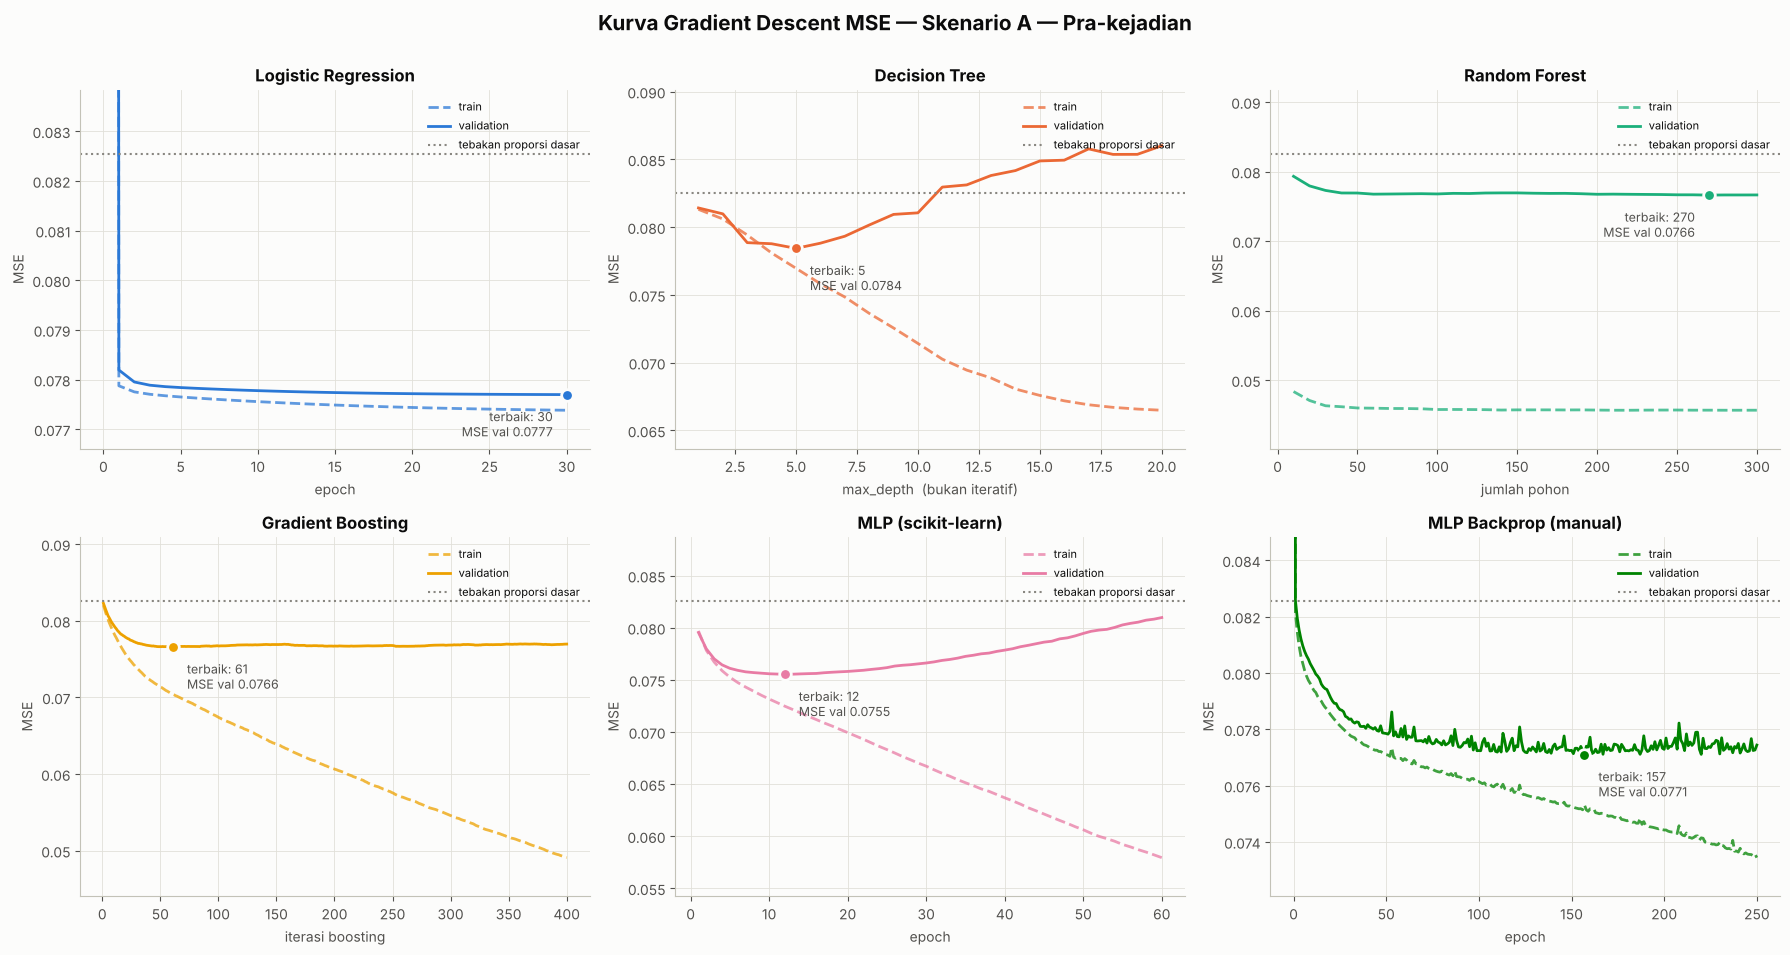

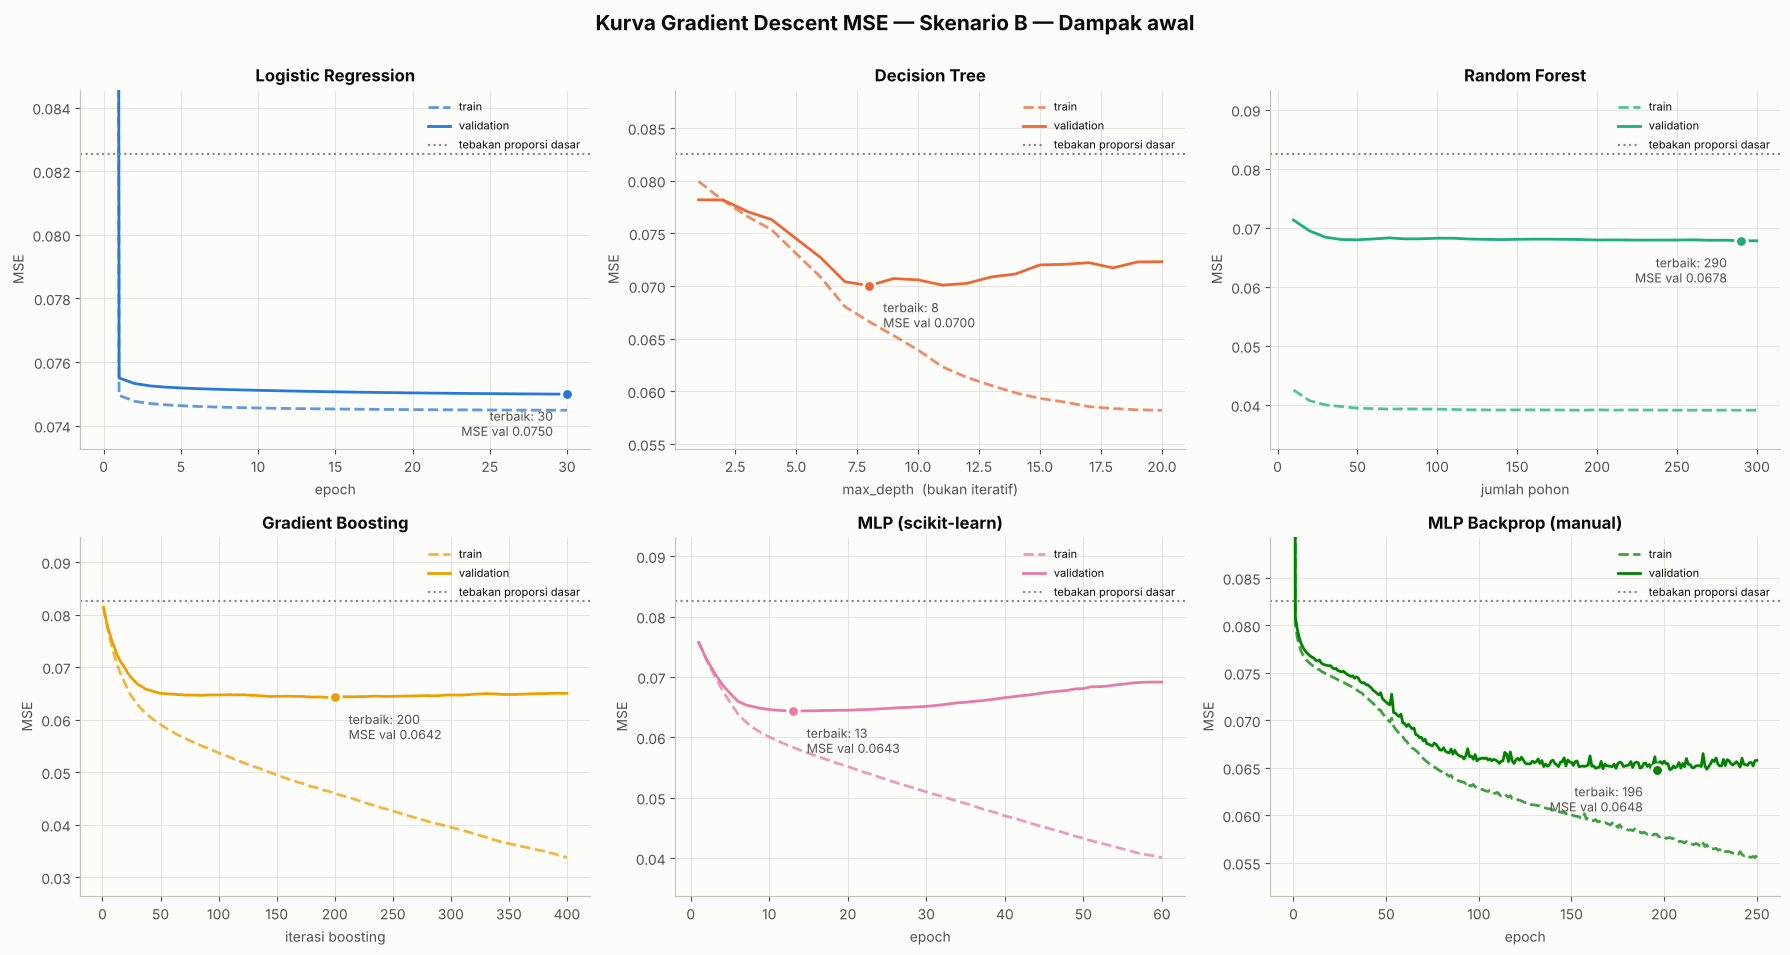

In [12]:
def plot_curves(s):
    fig, axes = plt.subplots(2, 3, figsize=(18, 9.5))
    for ax, name in zip(axes.ravel(), MODEL_ORDER):
        r, col = RESULTS[s][name], MODEL_COLORS[name]
        h = r['history']
        ax.plot(h.iter, h.mse_train, ls='--', color=col, alpha=0.75, label='train')
        ax.plot(h.iter, h.mse_val, color=col, label='validation')
        ax.axhline(MSE_PRIOR, color=MUTED, ls=':', lw=1.5, label='tebakan proporsi dasar')
        b = h.loc[h.mse_val.idxmin()]
        ax.scatter([b.iter], [b.mse_val], s=70, color=col, edgecolor=SURFACE, linewidth=2, zorder=5)
        near_right = b.iter > h.iter.min() + 0.7 * (h.iter.max() - h.iter.min())
        ax.annotate(f'terbaik: {int(b.iter)}\nMSE val {b.mse_val:.4f}', (b.iter, b.mse_val), textcoords='offset points',
                    xytext=(-10, -30) if near_right else (10, -30), ha='right' if near_right else 'left', fontsize=9, color=INK2)
        lo = min(h.mse_train.min(), h.mse_val.min()); hi = max(MSE_PRIOR, h.mse_val.quantile(0.9), h.mse_train.quantile(0.9))
        ax.set_ylim(lo - (hi - lo) * 0.15, hi + (hi - lo) * 0.25)
        note = '  (bukan iteratif)' if name == 'Decision Tree' else ''
        ax.set(title=name, xlabel=r['iter_label'] + note, ylabel='MSE')
        ax.legend(loc='upper right', fontsize=8)
    fig.suptitle(f'Kurva Gradient Descent MSE — Skenario {SCENARIOS[s]}', fontsize=15, fontweight='bold', y=1.0)
    plt.tight_layout(); savefig(fig, f'kj_gradient_descent_mse_{s}.png'); plt.show()

for s in SCENARIOS:
    plot_curves(s)

*Catatan membaca grafik*: sumbu-y dipotong agar bagian akhir kurva terlihat. Titik awal Logistic Regression (epoch 0, peluang 0.5 → MSE 0.5)
dan MLP Backprop (bobot acak) berada di atas batas grafik; keduanya turun tajam pada epoch-epoch pertama. Logistic Regression praktis sudah
konvergen setelah beberapa epoch: titik "terbaik" di epoch akhir hanya berbeda < 0.0001 dari epoch-epoch sebelumnya.

## 8. Evaluasi Data Uji: Classification Report & Confusion Matrix

In [13]:
rows, SCORES, PREDS = [], {}, {}
for s in SCENARIOS:
    Zva, Zte = DATA[s]['Z_val'], DATA[s]['Z_test']
    for name in MODEL_ORDER:
        r = RESULTS[s][name]; m = r['model']
        P = m.predict_proba(Zte); score = P[:, 1]
        thr, f1_val = best_threshold(y_val, m.predict_proba(Zva)[:, 1])
        yp = (score >= thr).astype(int)
        SCORES[(s, name)], PREDS[(s, name)] = score, yp
        h = r['history']; b = h.loc[h.mse_val.idxmin()]
        mse_t = mse_pdf(y_test, P)
        rows.append({'skenario': s, 'model': name, 'ambang': thr,
                     'accuracy': accuracy_score(y_test, yp),
                     'balanced_accuracy': balanced_accuracy_score(y_test, yp),
                     'precision_korban': precision_score(y_test, yp, zero_division=0),
                     'recall_korban': recall_score(y_test, yp),
                     'f1_korban': f1_score(y_test, yp),
                     'pr_auc': average_precision_score(y_test, score),
                     'roc_auc': roc_auc_score(y_test, score),
                     'mse_train': b.mse_train, 'mse_val': b.mse_val, 'mse_test': mse_t,
                     'mse_skill': 1 - mse_t / MSE_PRIOR,
                     'accuracy_ambang_0.5': accuracy_score(y_test, P.argmax(1)),
                     'iterasi_terbaik': f"{int(b.iter)} ({r['iter_label']})", 'waktu_latih_s': r['train_time']})
summary = pd.DataFrame(rows).set_index(['skenario', 'model'])

for s in SCENARIOS:
    display(Markdown(f'### Skenario {SCENARIOS[s]}'))
    for name in MODEL_ORDER:
        r = summary.loc[(s, name)]
        print(f'── {name}  (ambang = {r.ambang:.3f}) ──')
        print(classification_report(y_test, PREDS[(s, name)], target_names=CLASS_LABELS, digits=4))

### Skenario A — Pra-kejadian

── Logistic Regression  (ambang = 0.096) ──
                       precision    recall  f1-score   support

Tidak ada korban jiwa     0.9666    0.9300    0.9479      8452
      Ada korban jiwa     0.1555    0.2861    0.2015       381

             accuracy                         0.9022      8833
            macro avg     0.5610    0.6080    0.5747      8833
         weighted avg     0.9316    0.9022    0.9157      8833

── Decision Tree  (ambang = 0.188) ──
                       precision    recall  f1-score   support

Tidak ada korban jiwa     0.9622    0.9768    0.9695      8452
      Ada korban jiwa     0.2253    0.1496    0.1798       381

             accuracy                         0.9411      8833
            macro avg     0.5938    0.5632    0.5746      8833
         weighted avg     0.9305    0.9411    0.9354      8833

── Random Forest  (ambang = 0.144) ──
                       precision    recall  f1-score   support

Tidak ada korban jiwa     0.9668    0.9510    0.9588  

### Skenario B — Dampak awal

── Logistic Regression  (ambang = 0.158) ──
                       precision    recall  f1-score   support

Tidak ada korban jiwa     0.9661    0.9668    0.9664      8452
      Ada korban jiwa     0.2507    0.2467    0.2487       381

             accuracy                         0.9357      8833
            macro avg     0.6084    0.6067    0.6075      8833
         weighted avg     0.9352    0.9357    0.9355      8833

── Decision Tree  (ambang = 0.314) ──
                       precision    recall  f1-score   support

Tidak ada korban jiwa     0.9655    0.9870    0.9761      8452
      Ada korban jiwa     0.4301    0.2178    0.2892       381

             accuracy                         0.9538      8833
            macro avg     0.6978    0.6024    0.6327      8833
         weighted avg     0.9424    0.9538    0.9465      8833

── Random Forest  (ambang = 0.214) ──
                       precision    recall  f1-score   support

Tidak ada korban jiwa     0.9693    0.9795    0.9744  

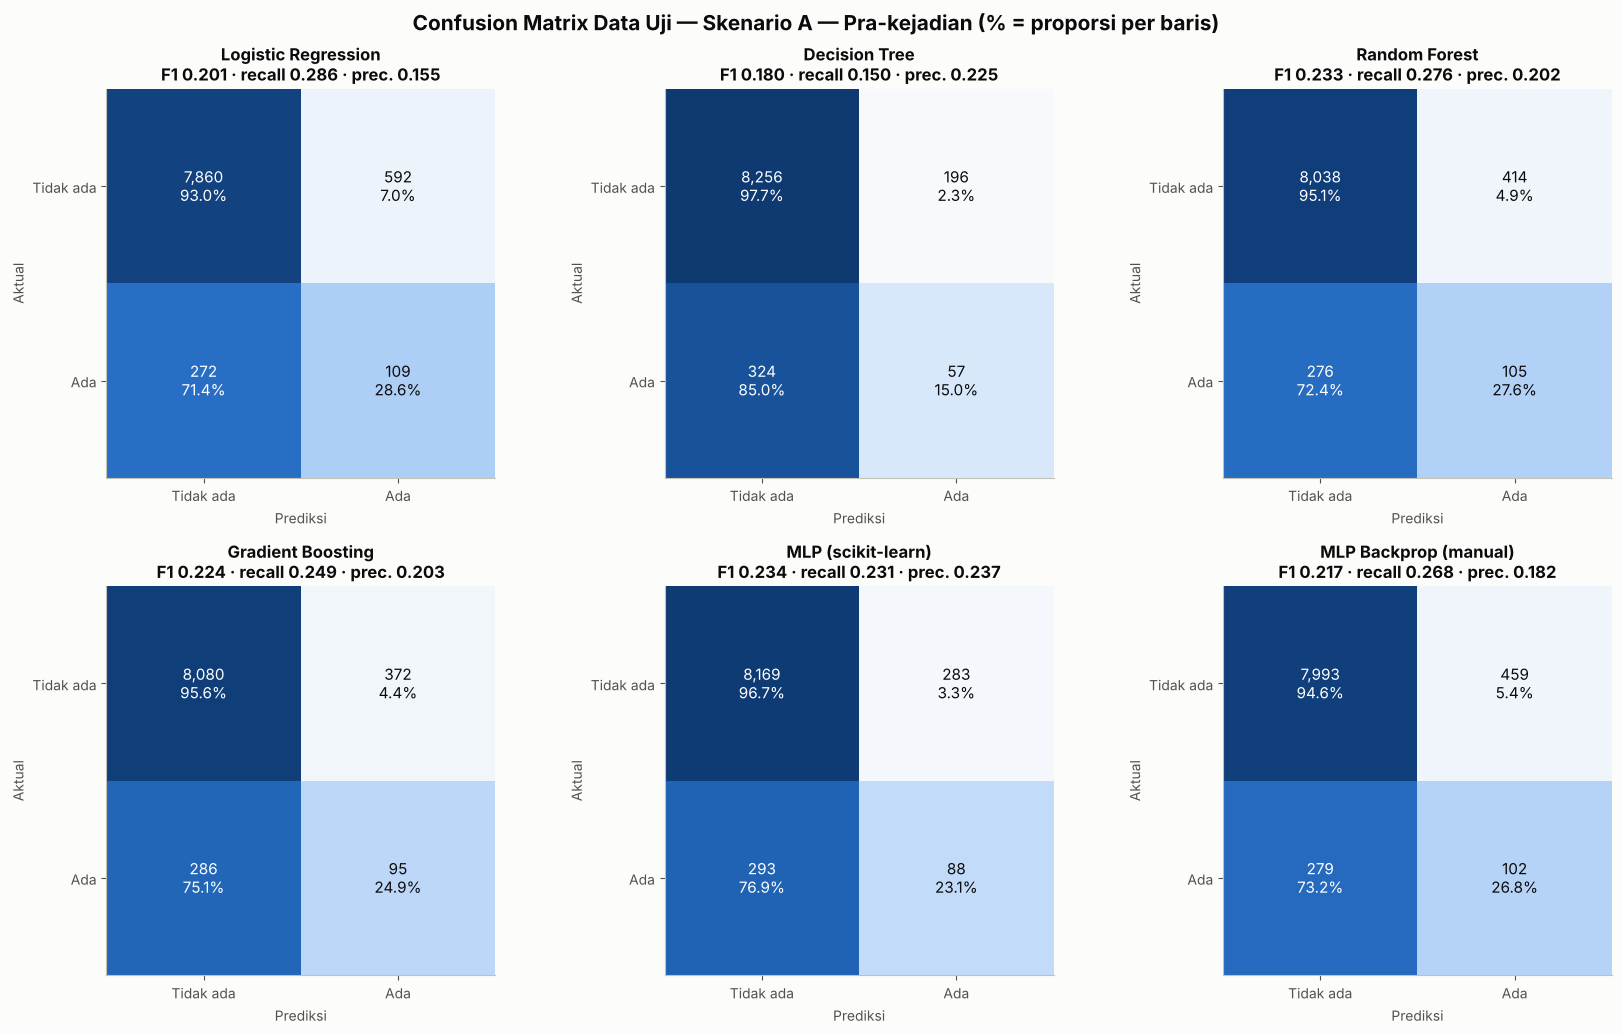

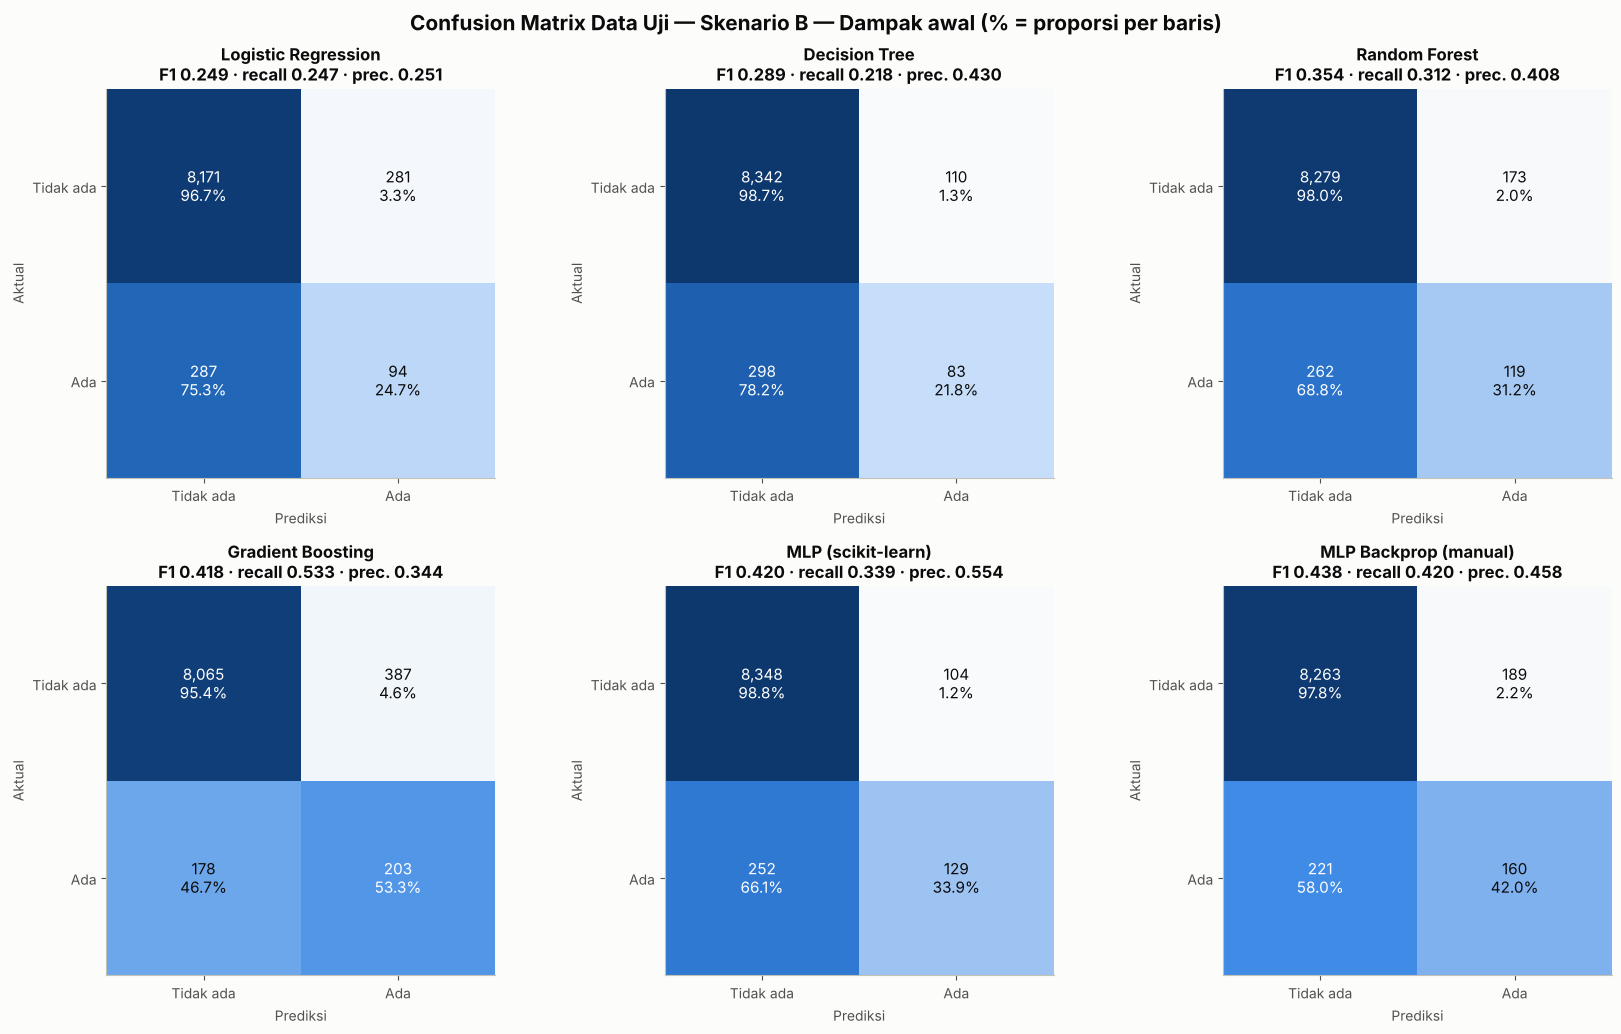

In [14]:
def plot_cms(s):
    fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
    for ax, name in zip(axes.ravel(), MODEL_ORDER):
        cm = confusion_matrix(y_test, PREDS[(s, name)], labels=[0, 1])
        cmn = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(cmn, cmap=CM_CMAP, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f'{cm[i, j]:,}\n{cmn[i, j]*100:.1f}%', ha='center', va='center', fontsize=11,
                        color='#ffffff' if cmn[i, j] > 0.5 else INK)
        ax.set_xticks([0, 1], ['Tidak ada', 'Ada']); ax.set_yticks([0, 1], ['Tidak ada', 'Ada']); ax.grid(False)
        r = summary.loc[(s, name)]
        ax.set(xlabel='Prediksi', ylabel='Aktual',
               title=f'{name}\nF1 {r.f1_korban:.3f} · recall {r.recall_korban:.3f} · prec. {r.precision_korban:.3f}')
    fig.suptitle(f'Confusion Matrix Data Uji — Skenario {SCENARIOS[s]} (% = proporsi per baris)', fontsize=15, fontweight='bold')
    plt.tight_layout(); savefig(fig, f'kj_confusion_matrices_{s}.png'); plt.show()

for s in SCENARIOS:
    plot_cms(s)

## 9. Validasi Silang Stratified 5-Fold

Mengukur kestabilan memakai metrik yang **tidak bergantung ambang**: MSE, PR-AUC, dan ROC-AUC, dengan hyperparameter terpilih di bagian 6.
Selisih antarmodel di satu data uji bisa sangat tipis, sehingga **MSE rata-rata 5-fold dipakai sebagai kriteria ke-4** dan penentu bila skor seri.

In [15]:
def make_model(s, name):
    p = RESULTS[s][name]['params']
    if name == 'Logistic Regression':
        return LogisticRegression(solver='saga', C=p['C'], max_iter=p['epochs'], tol=1e-12, random_state=RANDOM_SEED)
    if name == 'Decision Tree':
        return DecisionTreeClassifier(max_depth=p['max_depth'], min_samples_leaf=20, random_state=RANDOM_SEED)
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=p['n_estimators'], min_samples_leaf=3, max_features='sqrt',
                                      n_jobs=-1, random_state=RANDOM_SEED)
    if name == 'Gradient Boosting':
        return HistGradientBoostingClassifier(**{**GB_PARAMS, 'max_iter': p['max_iter']})
    if name == 'MLP (scikit-learn)':
        return MLPClassifier(**{**MLP_PARAMS, 'max_iter': p['epochs']})
    if name == 'MLP Backprop (manual)':
        return BackpropMLP(**{**BP_PARAMS, 'epochs': p['epochs']})

if RUN_CV:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    cv_rows = []; t0 = time.time()
    for s in SCENARIOS:
        X = df[FEATURES[s]]
        for fold, (tr, te) in enumerate(skf.split(X, y), 1):
            pre_f = make_preprocessor(s).fit(X.iloc[tr])
            Ztr_f, Zte_f = pre_f.transform(X.iloc[tr]), pre_f.transform(X.iloc[te])
            for name in MODEL_ORDER:
                P = make_model(s, name).fit(Ztr_f, y[tr]).predict_proba(Zte_f)
                cv_rows.append({'skenario': s, 'fold': fold, 'model': name, 'mse': mse_pdf(y[te], P),
                                'pr_auc': average_precision_score(y[te], P[:, 1]), 'roc_auc': roc_auc_score(y[te], P[:, 1])})
    cv = pd.DataFrame(cv_rows)
    cv_summary = cv.groupby(['skenario', 'model'])[['mse', 'pr_auc', 'roc_auc']].agg(['mean', 'std'])
    print(f'Selesai dalam {time.time() - t0:.0f} s')
    display(cv_summary.style.format('{:.4f}'))
    for s in SCENARIOS:
        c = cv_summary.loc[s]
        print(f"Skenario {s}: MSE CV terendah = {c[('mse', 'mean')].idxmin()} | PR-AUC CV tertinggi = {c[('pr_auc', 'mean')].idxmax()}")

Selesai dalam 175 s


Skenario A: MSE CV terendah = Random Forest | PR-AUC CV tertinggi = MLP (scikit-learn)
Skenario B: MSE CV terendah = Gradient Boosting | PR-AUC CV tertinggi = Gradient Boosting


## 10. Perbandingan & Pemilihan Model Terbaik

Peringkat dihitung **per skenario** dari: F1 kelas korban jiwa ↑ dan balanced accuracy ↑ (dari confusion matrix), MSE test ↓, dan
MSE rata-rata 5-fold ↓ (jika `RUN_CV`). Model terbaik = rata-rata peringkat terkecil; bila seri → MSE 5-fold (atau MSE test) terendah.

In [16]:
BEST = {}
RANK_COLS = ['rank_f1', 'rank_bal_acc', 'rank_mse'] + (['rank_mse_cv'] if RUN_CV else []) + ['skor_peringkat']
for c in RANK_COLS + ['mse_cv']:
    summary[c] = np.nan
for s in SCENARIOS:
    t = summary.loc[s]
    crit = {'rank_f1': t.f1_korban.rank(ascending=False, method='min'),
            'rank_bal_acc': t.balanced_accuracy.rank(ascending=False, method='min'),
            'rank_mse': t.mse_test.rank(ascending=True, method='min')}
    tiebreak = t.mse_test
    if RUN_CV:
        mse_cv = cv_summary.loc[s][('mse', 'mean')].reindex(t.index)
        crit['rank_mse_cv'] = mse_cv.rank(ascending=True, method='min')
        tiebreak = mse_cv
    rk = pd.DataFrame(crit); rk['skor_peringkat'] = rk.mean(axis=1)
    if RUN_CV:
        rk['mse_cv'] = mse_cv
    mask = summary.index.get_level_values('skenario') == s
    for c in rk.columns:
        summary.loc[mask, c] = rk[c].values
    BEST[s] = rk.assign(_tb=tiebreak).sort_values(['skor_peringkat', '_tb']).index[0]

cols = ['accuracy', 'balanced_accuracy', 'precision_korban', 'recall_korban', 'f1_korban', 'pr_auc', 'roc_auc',
        'mse_test', 'mse_cv', 'mse_skill', 'ambang', 'skor_peringkat']
show = summary[cols].sort_values(['skenario', 'skor_peringkat'])
display(show.style.format('{:.4f}').format({'skor_peringkat': '{:.2f}', 'ambang': '{:.3f}'})
        .highlight_max(subset=['f1_korban', 'balanced_accuracy', 'pr_auc'], color='#cde2fb')
        .highlight_min(subset=['mse_test'], color='#cde2fb'))
for s in SCENARIOS:
    r = summary.loc[(s, BEST[s])]
    display(Markdown(f'**🏆 Terbaik skenario {SCENARIOS[s]}: {BEST[s]}** — F1 {r.f1_korban:.3f}, recall {r.recall_korban:.3f}, '
                     f'precision {r.precision_korban:.3f}, balanced acc. {r.balanced_accuracy:.3f}, MSE {r.mse_test:.4f} '
                     f'(skill {r.mse_skill*100:.1f}%), PR-AUC {r.pr_auc:.3f}'))
print(f"Pembanding: accuracy 'selalu tidak ada korban' = {(y_test == 0).mean():.4f}; "
      f"accuracy semua model pada ambang 0.5 = {summary['accuracy_ambang_0.5'].min():.4f}–{summary['accuracy_ambang_0.5'].max():.4f}")

**🏆 Terbaik skenario A — Pra-kejadian: Random Forest** — F1 0.233, recall 0.276, precision 0.202, balanced acc. 0.613, MSE 0.0770 (skill 6.7%), PR-AUC 0.170

**🏆 Terbaik skenario B — Dampak awal: Gradient Boosting** — F1 0.418, recall 0.533, precision 0.344, balanced acc. 0.744, MSE 0.0635 (skill 23.1%), PR-AUC 0.408

Pembanding: accuracy 'selalu tidak ada korban' = 0.9569; accuracy semua model pada ambang 0.5 = 0.9564–0.9623


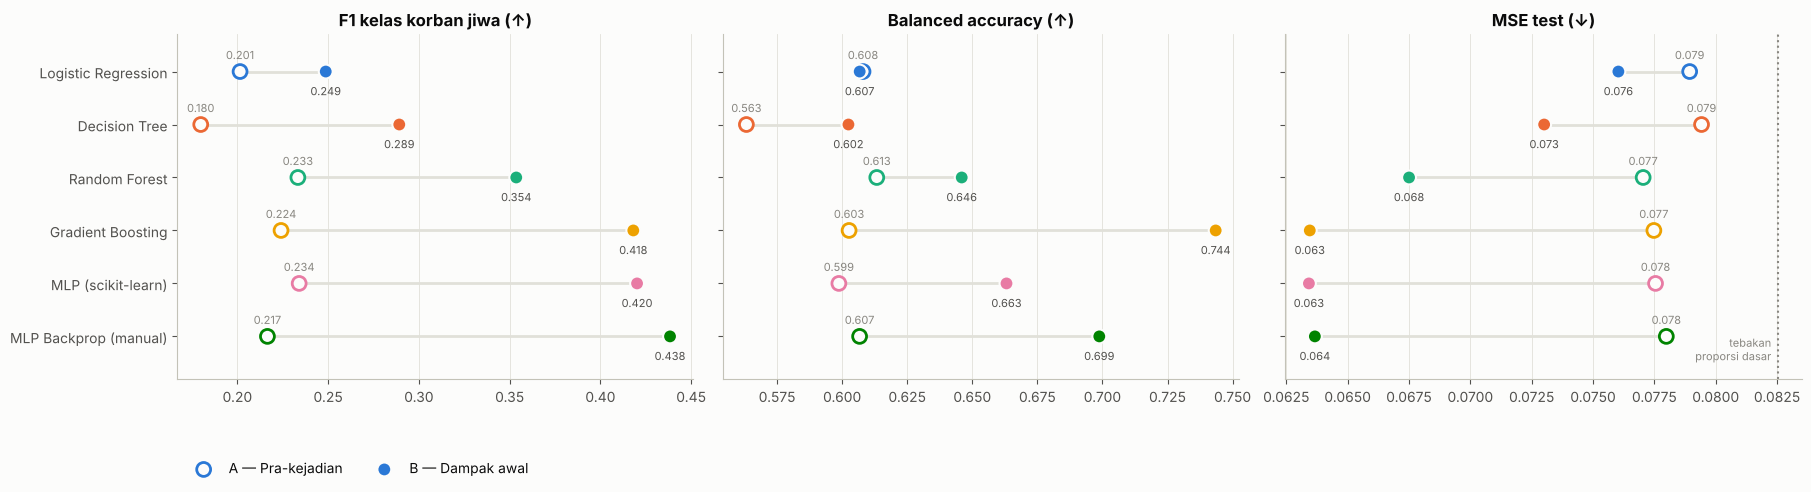

In [17]:
# Dot plot: setiap model, skenario A (lingkaran kosong) vs B (lingkaran penuh)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), layout='constrained')
yy = np.arange(len(MODEL_ORDER))
for ax, (col, title) in zip(axes, [('f1_korban', 'F1 kelas korban jiwa (↑)'),
                                   ('balanced_accuracy', 'Balanced accuracy (↑)'),
                                   ('mse_test', 'MSE test (↓)')]):
    a = summary.loc['A', col].reindex(MODEL_ORDER).values
    b = summary.loc['B', col].reindex(MODEL_ORDER).values
    ax.hlines(yy, a, b, color=GRID, lw=2, zorder=1)
    cols_m = [MODEL_COLORS[m] for m in MODEL_ORDER]
    ax.scatter(a, yy, s=100, facecolor=SURFACE, edgecolor=cols_m, linewidth=2, zorder=3, label='A — Pra-kejadian')
    ax.scatter(b, yy, s=100, color=cols_m, edgecolor=SURFACE, linewidth=1.5, zorder=3, label='B — Dampak awal')
    for i in range(len(yy)):
        ax.annotate(f'{a[i]:.3f}', (a[i], i), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=8, color=MUTED)
        ax.annotate(f'{b[i]:.3f}', (b[i], i), textcoords='offset points', xytext=(0, -17), ha='center', fontsize=8, color=INK2)
    if col == 'mse_test':
        ax.axvline(MSE_PRIOR, color=MUTED, ls=':', lw=1.5)
        ax.annotate('tebakan\nproporsi dasar', (MSE_PRIOR, len(yy) - 0.5), textcoords='offset points', xytext=(-5, 0),
                    ha='right', fontsize=8, color=MUTED, va='bottom')
    ax.set_ylim(len(yy) - 0.2, -0.7)
    ax.set_yticks(yy, MODEL_ORDER if ax is axes[0] else [''] * len(yy))
    ax.grid(axis='y', visible=False); ax.set(title=title)
axes[0].legend(loc='lower left', bbox_to_anchor=(0, -0.32), ncol=2)
savefig(fig, 'kj_perbandingan_model.png'); plt.show()

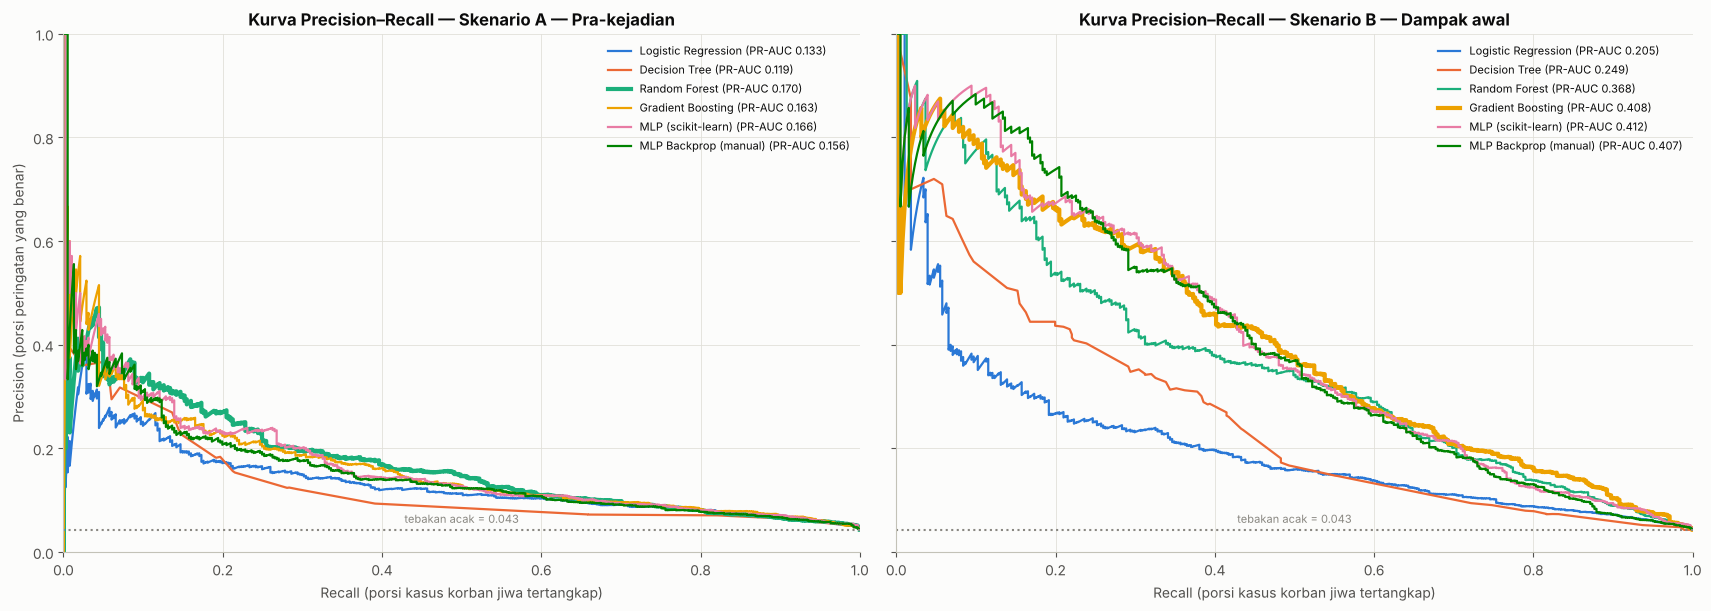

In [18]:
# Kurva Precision–Recall: seberapa banyak kasus korban jiwa tertangkap vs seberapa tepat peringatannya
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True, layout='constrained')
for ax, s in zip(axes, SCENARIOS):
    for name in MODEL_ORDER:
        prec, rec, _ = precision_recall_curve(y_test, SCORES[(s, name)])
        lw = 3 if name == BEST[s] else 1.6
        ax.plot(rec, prec, color=MODEL_COLORS[name], lw=lw,
                label=f"{name} (PR-AUC {summary.loc[(s, name), 'pr_auc']:.3f})")
    ax.axhline(y_test.mean(), color=MUTED, ls=':', lw=1.5)
    ax.annotate(f'tebakan acak = {y_test.mean():.3f}', (0.5, y_test.mean()), textcoords='offset points', xytext=(0, 5),
                ha='center', fontsize=8, color=MUTED)
    ax.set(title=f'Kurva Precision–Recall — Skenario {SCENARIOS[s]}', xlabel='Recall (porsi kasus korban jiwa tertangkap)',
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc='upper right', fontsize=8)
axes[0].set_ylabel('Precision (porsi peringatan yang benar)')
savefig(fig, 'kj_precision_recall.png'); plt.show()

## 11. Analisis Model Terbaik

### 11.1 Fitur paling berpengaruh (*permutation importance*, skor PR-AUC)

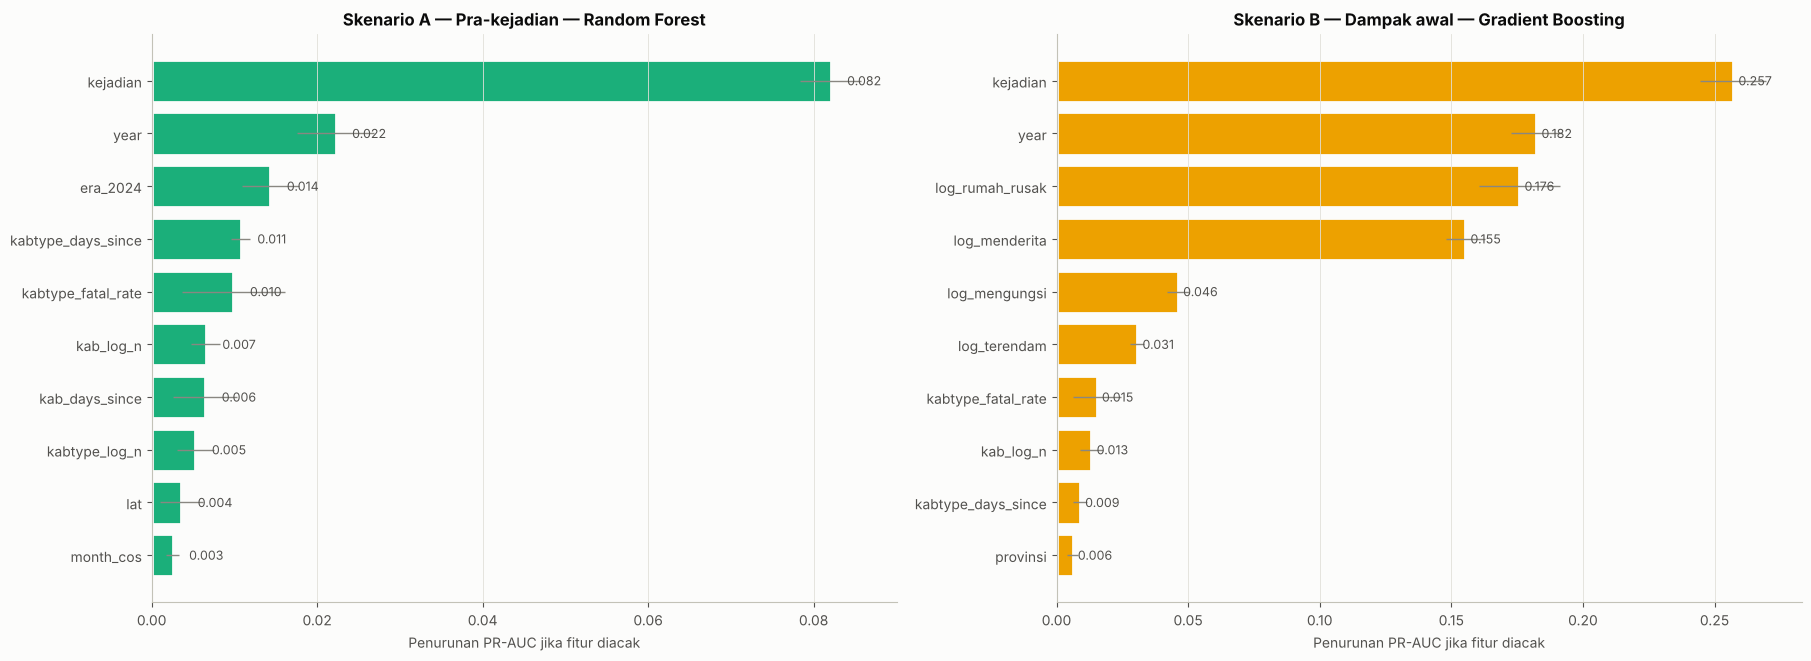

,A,B
kejadian,0.0820,0.2571
year,0.0222,0.1823
era_2024,0.0143,0.0000
kabtype_days_since,0.0108,0.0089
kabtype_fatal_rate,0.0099,0.0152
kab_log_n,0.0065,0.0133
kab_days_since,0.0065,0.0031
kabtype_log_n,0.0053,0.0052
lat,0.0036,0.0051
month_cos,0.0025,-0.0003


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), layout='constrained')
IMP = {}
for ax, s in zip(axes, SCENARIOS):
    pipe = Pipeline([('pre', DATA[s]['pre']), ('model', RESULTS[s][BEST[s]]['model'])])
    pi = permutation_importance(pipe, DATA[s]['X_test'], y_test, scoring='average_precision', n_repeats=5,
                                random_state=RANDOM_SEED, n_jobs=1)
    imp = (pd.DataFrame({'penurunan_pr_auc': pi.importances_mean, 'std': pi.importances_std},
                        index=DATA[s]['X_test'].columns).sort_values('penurunan_pr_auc', ascending=False))
    IMP[s] = imp
    top = imp.head(10)[::-1]
    ax.barh(top.index, top.penurunan_pr_auc, xerr=top['std'], color=MODEL_COLORS[BEST[s]], edgecolor=SURFACE, linewidth=2,
            error_kw={'ecolor': MUTED, 'lw': 1})
    for i, v in enumerate(top.penurunan_pr_auc):
        ax.text(max(v, 0) + 0.002, i, f'{v:.3f}', va='center', fontsize=9, color=INK2)
    ax.set(title=f'Skenario {SCENARIOS[s]} — {BEST[s]}', xlabel='Penurunan PR-AUC jika fitur diacak'); ax.grid(axis='y', visible=False)
savefig(fig, 'kj_feature_importance.png'); plt.show()
display(pd.concat({s: IMP[s].penurunan_pr_auc for s in SCENARIOS}, axis=1).round(4))

### 11.2 Memilih ambang sesuai kapasitas tim
Ambang keputusan adalah **keputusan operasional**, bukan sekadar teknis: ambang rendah menangkap lebih banyak kasus korban jiwa
tetapi memicu lebih banyak peringatan. Grafik berikut membantu stakeholder memilih titik yang sesuai kapasitas respons.

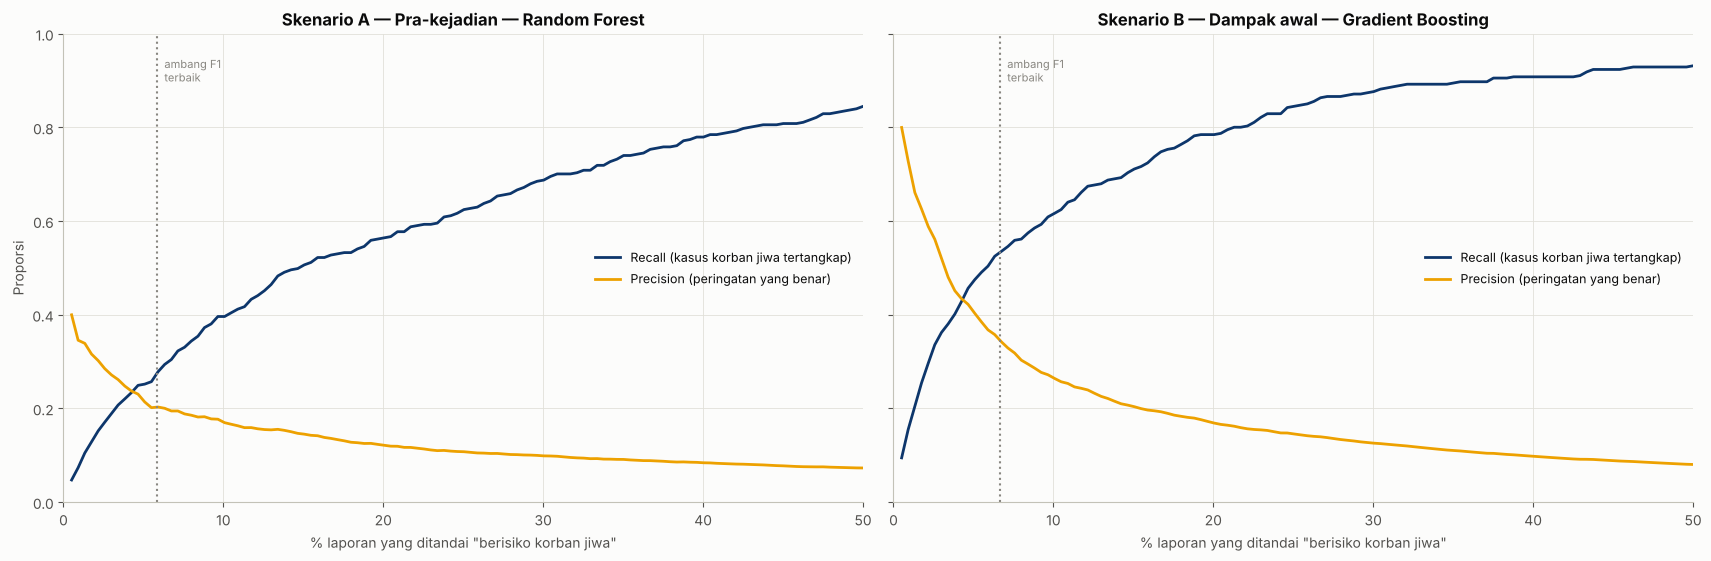

model  recall  precision  \
skenario % laporan ditandai                                         
A        5                       Random Forest   0.249      0.215   
         10                      Random Forest   0.396      0.171   
         20                      Random Forest   0.564      0.122   
B        5                   Gradient Boosting   0.475      0.410   
         10                  Gradient Boosting   0.617      0.266   
         20                  Gradient Boosting   0.785      0.169   

                             lift vs acak  
skenario % laporan ditandai                
A        5                          4.983  
         10                         3.960  
         20                         2.821  
B        5                          9.494  
         10                         6.163  
         20                         3.923

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True, layout='constrained')
TRADEOFF = {}
for ax, s in zip(axes, SCENARIOS):
    score = SCORES[(s, BEST[s])]
    ths = np.unique(np.quantile(score, np.linspace(0.5, 0.995, 120)))
    t = pd.DataFrame({'ambang': ths,
                      'recall': [recall_score(y_test, score >= th) for th in ths],
                      'precision': [precision_score(y_test, score >= th, zero_division=0) for th in ths],
                      'pct_ditandai': [(score >= th).mean() * 100 for th in ths]})
    TRADEOFF[s] = t
    ax.plot(t.pct_ditandai, t.recall, color=CLASS_COLORS[1], label='Recall (kasus korban jiwa tertangkap)')
    ax.plot(t.pct_ditandai, t.precision, color=MODEL_COLORS['Gradient Boosting'], label='Precision (peringatan yang benar)')
    thr = summary.loc[(s, BEST[s]), 'ambang']
    ax.axvline((score >= thr).mean() * 100, color=MUTED, ls=':', lw=1.5)
    ax.annotate('ambang F1\nterbaik', ((score >= thr).mean() * 100, 0.95), textcoords='offset points', xytext=(5, 0),
                fontsize=8, color=MUTED, va='top')
    ax.set(title=f'Skenario {SCENARIOS[s]} — {BEST[s]}', xlabel='% laporan yang ditandai "berisiko korban jiwa"',
           xlim=(0, 50), ylim=(0, 1))
    ax.legend(loc='center right', fontsize=9)
axes[0].set_ylabel('Proporsi')
savefig(fig, 'kj_tradeoff_ambang.png'); plt.show()

# Ringkasan: berapa kasus tertangkap jika menandai 5%, 10%, 20% laporan teratas
rows = []
for s in SCENARIOS:
    score = SCORES[(s, BEST[s])]
    for pct in [5, 10, 20]:
        th = np.quantile(score, 1 - pct / 100); flag = score >= th
        rows.append({'skenario': s, 'model': BEST[s], '% laporan ditandai': pct,
                     'recall': recall_score(y_test, flag), 'precision': precision_score(y_test, flag),
                     'lift vs acak': precision_score(y_test, flag) / y_test.mean()})
display(pd.DataFrame(rows).set_index(['skenario', '% laporan ditandai']).round(3))

### 11.3 Kinerja per jenis bencana

In [21]:
s = 'B'
ev = DATA[s]['X_test'][['kejadian']].copy()
ev['aktual'], ev['prediksi'], ev['p'] = y_test, PREDS[(s, BEST[s])], SCORES[(s, BEST[s])]
ev['pred_A'] = PREDS[('A', BEST['A'])]
per_type = (ev.groupby('kejadian')
              .apply(lambda g: pd.Series({
                  'n': len(g), 'kasus_korban': int(g.aktual.sum()),
                  '% korban aktual': g.aktual.mean() * 100,
                  'rata2_peluang_prediksi_%': g.p.mean() * 100,
                  'recall_B': recall_score(g.aktual, g.prediksi, zero_division=0) if g.aktual.sum() else np.nan,
                  'recall_A': recall_score(g.aktual, g.pred_A, zero_division=0) if g.aktual.sum() else np.nan}))
              .sort_values('kasus_korban', ascending=False))
display(per_type.round(3))

,n,kasus_korban,% korban aktual,rata2_peluang_prediksi_%,recall_B,recall_A
kejadian,,,,,,
BANJIR,2883.0,167.0,5.793,5.230,0.497,0.192
TANAH LONGSOR,1653.0,117.0,7.078,7.550,0.692,0.470
CUACA EKSTREM,2365.0,65.0,2.748,2.427,0.354,0.108
GEMPABUMI,109.0,16.0,14.679,15.760,0.688,0.562
KEBAKARAN HUTAN DAN LAHAN,1565.0,7.0,0.447,0.474,0.000,0.000
GELOMBANG PASANG DAN ABRASI,74.0,5.0,6.757,4.318,0.400,0.000
ERUPSI GUNUNG API,26.0,4.0,15.385,13.430,0.750,0.500
KEKERINGAN,158.0,0.0,0.000,0.485,NaN,NaN


## 12. Uji *Out-of-Time* 2026 & Kaitan dengan Klaster Risiko

Model terbaik tiap skenario dilatih ulang dengan data **2015–2025** saja, lalu diuji pada laporan **2026** (periode clustering rekan).
Ambang memakai nilai dari bagian 8. Label klaster K-Means (k = 4) hanya dipakai sebagai lensa analisis, tidak sebagai fitur.

,model,n,kasus_korban,recall,precision,f1,pr_auc,roc_auc,mse
skenario,,,,,,,,,
A,Random Forest,2285,115,0.3826,0.2268,0.2848,0.2596,0.8094,0.0855
B,Gradient Boosting,2285,115,0.6000,0.5000,0.5455,0.6271,0.9160,0.0580


,n_laporan,kasus_korban,pct_korban_aktual,peluang_A,peluang_B,pct_ditandai_A,pct_ditandai_B
cluster_short,,,,,,,
Tingkat I - Rendah/Sporadis,573,9,1.57,4.17,2.25,6.63,2.62
Tingkat II - Kronis/Multi-Hazard,1318,72,5.46,5.12,3.66,6.60,5.24
Tingkat III - Kemanusiaan Akut,356,17,4.78,8.05,6.28,15.17,10.96
Tingkat IV - Katastropik Ekstrem,37,17,45.95,14.32,23.67,37.84,37.84


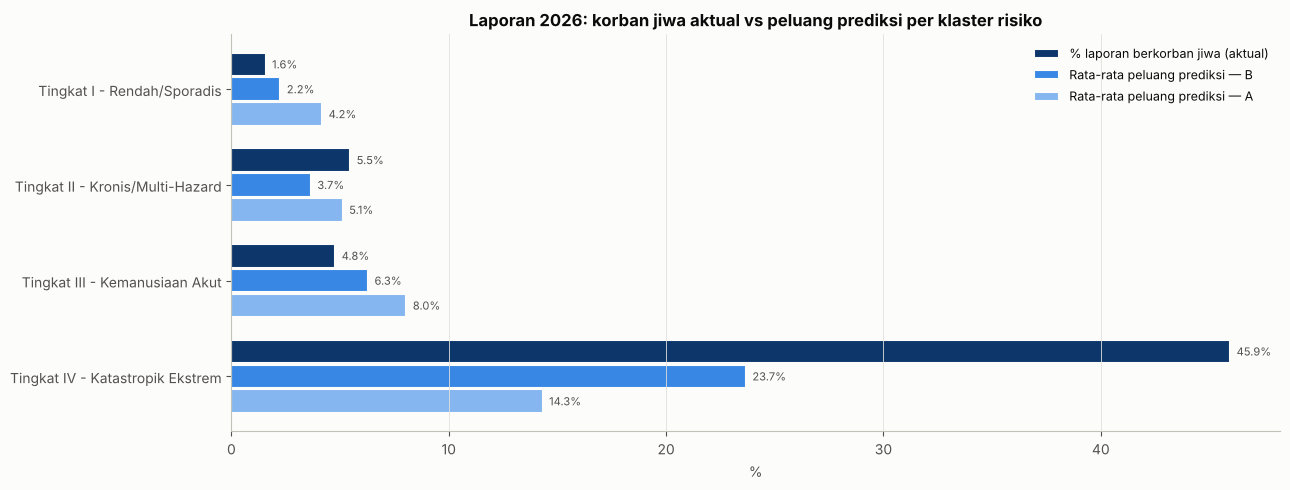

In [22]:
mask_tr, mask_te = (df.year <= 2025).values, (df.year == 2026).values
y26 = y[mask_te]
d26 = df.loc[mask_te, ['id_kab', 'kabkot', 'kejadian']].copy()
d26['aktual'] = y26
oot_rows = []
for s in SCENARIOS:
    X = df[FEATURES[s]]
    pre = make_preprocessor(s).fit(X[mask_tr])
    m = make_model(s, BEST[s]).fit(pre.transform(X[mask_tr]), y[mask_tr])
    P26 = m.predict_proba(pre.transform(X[mask_te])); score = P26[:, 1]
    thr = summary.loc[(s, BEST[s]), 'ambang']; yp = (score >= thr).astype(int)
    d26[f'p_{s}'], d26[f'pred_{s}'] = score, yp
    oot_rows.append({'skenario': s, 'model': BEST[s], 'n': len(y26), 'kasus_korban': int(y26.sum()),
                     'recall': recall_score(y26, yp), 'precision': precision_score(y26, yp, zero_division=0),
                     'f1': f1_score(y26, yp), 'pr_auc': average_precision_score(y26, score),
                     'roc_auc': roc_auc_score(y26, score), 'mse': mse_pdf(y26, P26)})
oot = pd.DataFrame(oot_rows).set_index('skenario')
display(oot.round(4))

clusters = pd.read_csv(CLUSTER_FILE, usecols=['id_kab', 'cluster', 'cluster_short'])
d26 = d26.merge(clusters, on='id_kab', how='left')
per_cluster = (d26.dropna(subset=['cluster']).groupby(['cluster', 'cluster_short'])
                 .agg(n_laporan=('aktual', 'size'), kasus_korban=('aktual', 'sum'),
                      pct_korban_aktual=('aktual', lambda v: v.mean() * 100),
                      peluang_A=('p_A', lambda v: v.mean() * 100), peluang_B=('p_B', lambda v: v.mean() * 100),
                      pct_ditandai_A=('pred_A', lambda v: v.mean() * 100), pct_ditandai_B=('pred_B', lambda v: v.mean() * 100))
                 .reset_index(level=0, drop=True))
display(per_cluster.round(2))

fig, ax = plt.subplots(figsize=(13, 5))
yy = np.arange(len(per_cluster)); h = 0.26
for k, (col, lab, color) in enumerate([('pct_korban_aktual', '% laporan berkorban jiwa (aktual)', CLASS_COLORS[1]),
                                       ('peluang_B', 'Rata-rata peluang prediksi — B', '#3987e5'),
                                       ('peluang_A', 'Rata-rata peluang prediksi — A', CLASS_COLORS[0])]):
    v = per_cluster[col].values
    ax.barh(yy + (k - 1) * h, v, height=h * 0.95, color=color, edgecolor=SURFACE, linewidth=1.5, label=lab)
    for i, x in enumerate(v):
        ax.text(x + 0.3, i + (k - 1) * h, f'{x:.1f}%', va='center', fontsize=8, color=INK2)
ax.set_yticks(yy, per_cluster.index); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set(title='Laporan 2026: korban jiwa aktual vs peluang prediksi per klaster risiko', xlabel='%')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout(); savefig(fig, 'kj_out_of_time_2026_klaster.png'); plt.show()

## 13. Simpan Hasil

In [23]:
summary.to_csv(DATA_DIR / 'korban_jiwa_metrics_comparison.csv', encoding='utf-8-sig')
pred_out = df.iloc[idx_test][['date', 'provinsi', 'kabkot', 'kejadian']].copy()
pred_out['ada_korban_jiwa_aktual'] = y_test
for s in SCENARIOS:
    pred_out[f'peluang_{s}'] = SCORES[(s, BEST[s])].round(4)
    pred_out[f'prediksi_{s}'] = PREDS[(s, BEST[s])]
pred_out.to_csv(DATA_DIR / 'korban_jiwa_test_predictions.csv', index=False, encoding='utf-8-sig')
if RUN_CV:
    cv.to_csv(DATA_DIR / 'korban_jiwa_cv_5fold.csv', index=False, encoding='utf-8-sig')
print('Tersimpan:')
for f in ['korban_jiwa_metrics_comparison.csv', 'korban_jiwa_test_predictions.csv', 'korban_jiwa_cv_5fold.csv']:
    print('  data/processed/' + f)
for f in sorted(FIG_DIR.glob('kj_*.png')):
    print('  reports/figures/' + f.name)

Tersimpan:
  data/processed/korban_jiwa_metrics_comparison.csv
  data/processed/korban_jiwa_test_predictions.csv
  data/processed/korban_jiwa_cv_5fold.csv
  reports/figures/kj_confusion_matrices_A.png
  reports/figures/kj_confusion_matrices_B.png
  reports/figures/kj_distribusi_target.png
  reports/figures/kj_feature_importance.png
  reports/figures/kj_gradient_descent_mse_A.png
  reports/figures/kj_gradient_descent_mse_B.png
  reports/figures/kj_out_of_time_2026_klaster.png
  reports/figures/kj_perbandingan_model.png
  reports/figures/kj_precision_recall.png
  reports/figures/kj_tradeoff_ambang.png


## 14. Ringkasan Hasil & Insight

In [24]:
lines = []
for s in SCENARIOS:
    r = summary.loc[(s, BEST[s])]
    lines.append(f"- **Skenario {SCENARIOS[s]}** → terbaik **{BEST[s]}**: F1 {r.f1_korban:.3f}, recall {r.recall_korban:.3f}, "
                 f"precision {r.precision_korban:.3f}, balanced acc. {r.balanced_accuracy:.3f}, PR-AUC {r.pr_auc:.3f}, "
                 f"MSE {r.mse_test:.4f} (skill {r.mse_skill*100:.1f}%), accuracy {r.accuracy:.4f}")
lines.append(f"- Pembanding: MSE tebakan proporsi dasar {MSE_PRIOR:.4f}; accuracy 'selalu tidak ada korban' {(y_test == 0).mean():.4f}")
for s in SCENARIOS:
    lines.append(f"- Fitur terpenting {s}: " + ', '.join(f'{i} ({v:.3f})' for i, v in IMP[s].penurunan_pr_auc.head(4).items()))
for s in SCENARIOS:
    o = oot.loc[s]
    lines.append(f"- Out-of-time 2026 ({s}): recall {o.recall:.3f}, precision {o.precision:.3f}, PR-AUC {o.pr_auc:.3f}, MSE {o.mse:.4f}")
display(Markdown('\n'.join(lines)))

- **Skenario A — Pra-kejadian** → terbaik **Random Forest**: F1 0.233, recall 0.276, precision 0.202, balanced acc. 0.613, PR-AUC 0.170, MSE 0.0770 (skill 6.7%), accuracy 0.9219
- **Skenario B — Dampak awal** → terbaik **Gradient Boosting**: F1 0.418, recall 0.533, precision 0.344, balanced acc. 0.744, PR-AUC 0.408, MSE 0.0635 (skill 23.1%), accuracy 0.9360
- Pembanding: MSE tebakan proporsi dasar 0.0825; accuracy 'selalu tidak ada korban' 0.9569
- Fitur terpenting A: kejadian (0.082), year (0.022), era_2024 (0.014), kabtype_days_since (0.011)
- Fitur terpenting B: kejadian (0.257), year (0.182), log_rumah_rusak (0.176), log_menderita (0.155)
- Out-of-time 2026 (A): recall 0.383, precision 0.227, PR-AUC 0.260, MSE 0.0855
- Out-of-time 2026 (B): recall 0.600, precision 0.500, PR-AUC 0.627, MSE 0.0580

### Insight dari Klasifikasi Korban Jiwa

*(Angka dari eksekusi notebook ini dengan `RANDOM_SEED = 42`; dapat bergeser sedikit bila versi library berbeda.)*

#### 1. Jawaban singkat
Korban jiwa **jauh lebih sulit diprediksi** dibanding tingkat dampak. Ini wajar, karena kematian adalah kejadian langka dan sangat dipengaruhi
faktor yang tidak tercatat (lokasi persis pemukiman, waktu kejadian, kesiapsiagaan warga).
- **Dari informasi pra-kejadian saja (A)**, sinyalnya lemah: MSE hanya 6.7% lebih baik dari tebakan proporsi dasar, dan model menangkap
  ±28% kasus korban jiwa dengan precision ±20%.
- **Setelah data kerusakan & pengungsian masuk (B)**, model menjadi berguna: MSE 23% lebih baik dari tebakan dasar, recall ±53%,
  dan **PR-AUC naik 2.4× (0.170 → 0.408)**.

#### 2. Accuracy menyesatkan untuk target ini
Menebak "tidak ada korban jiwa" untuk semua laporan sudah menghasilkan accuracy **0.957**. Semua 12 model pada ambang default 0.5 juga
berada di 0.956–0.962 karena hanya sedikit sekali kasus korban jiwa yang tertangkap. Karena itu evaluasi dibaca dari **confusion matrix**
(recall, precision, F1 kelas korban jiwa) dan **MSE**, bukan accuracy.

#### 3. Tiga model terbaik per skenario
| Skenario | Peringkat | Model | F1 korban | Recall | Precision | Balanced acc. | MSE test | MSE CV 5-fold |
|---|---|---|---|---|---|---|---|---|
| **B — Dampak awal** | 1 | **Gradient Boosting** | 0.418 | **0.533** | 0.344 | **0.744** | 0.0635 | **0.0642** |
| | 2 | MLP (scikit-learn) | 0.420 | 0.339 | **0.554** | 0.663 | **0.0634** | 0.0655 |
| | 3 | MLP Backprop (manual) | **0.438** | 0.420 | 0.459 | 0.699 | 0.0637 | 0.0664 |
| **A — Pra-kejadian** | 1 | **Random Forest** | 0.233 | 0.276 | 0.202 | 0.613 | **0.0770** | **0.0764** |
| | 2 | Gradient Boosting | 0.224 | 0.249 | 0.203 | 0.603 | 0.0775 | 0.0767 |
| | 3 | MLP (scikit-learn) | 0.234 | 0.231 | 0.237 | 0.599 | 0.0775 | 0.0768 |

- Di skenario B, ketiga model teratas hampir seri pada MSE test. **Gradient Boosting dipilih** karena paling stabil di validasi silang
  (MSE & PR-AUC 5-fold terbaik) dan menangkap paling banyak kasus korban jiwa (recall 0.53).
- **MLP Backprop manual** (rumus materi Multi Perceptron) mencapai F1 tertinggi di skenario B. Implementasi teori backpropagation
  setara dengan library, asalkan laju belajar μ cukup besar (0.5) dan epoch cukup panjang (±200) untuk kelas yang langka.

#### 4. Kurva Gradient Descent MSE
- **MLP scikit-learn** optimal di epoch 12–13, lalu MSE validation naik sementara MSE train terus turun (*overfitting*); *early stopping* wajib.
- **Gradient Boosting** butuh 200 iterasi di skenario B tetapi hanya 61 di skenario A: fitur dampak memberi lebih banyak pola untuk dipelajari.
- Di skenario A, kurva validation semua model hanya turun sedikit di bawah garis tebakan dasar (0.0755–0.0784 vs 0.0825).
  Ini bukti visual bahwa jenis–lokasi–waktu saja **memuat sedikit informasi** tentang korban jiwa.

#### 5. Confusion matrix & pilihan ambang = keputusan operasional
Dengan model terbaik skenario B, jika tim hanya mampu menindaklanjuti sebagian laporan:

| Laporan yang ditandai | Kasus korban jiwa tertangkap (recall) | Peringatan yang benar (precision) | Lebih baik dari acak |
|---|---|---|---|
| 5% teratas | 47.5% | 41.0% | 9.5× |
| 10% teratas | 61.7% | 26.6% | 6.2× |
| 20% teratas | 78.5% | 16.9% | 3.9× |

Pada skenario A, menandai 10% laporan teratas hanya menangkap 39.6% kasus. Model ini paling tepat dipakai sebagai **daftar prioritas
verifikasi korban**, bukan penentu ya/tidak.

#### 6. Faktor penentu korban jiwa
- **Jenis bencana** tetap faktor terkuat di kedua skenario. Per laporan, gempabumi (12%), erupsi (8%), dan **tanah longsor (8%)** jauh lebih
  mematikan dibanding cuaca ekstrem (2.5%), karhutla (0.5%), dan kekeringan (0.1%). Tanah longsor paling penting secara operasional
  karena jumlah laporannya besar (8.000+).
- Di skenario B, **jumlah rumah rusak** dan **warga menderita** adalah sinyal terkuat berikutnya: semakin besar kerusakan fisik, semakin
  mungkin ada korban jiwa.
- **Tahun/era pelaporan** ikut penting di skenario B karena angka "menderita" baru rutin dicatat sejak 2024. Model perlu tahu era pelaporan
  untuk menafsirkan angka dampak dengan benar.
- Riwayat korban jiwa di kab/kota yang sama (`kabtype_fatal_rate`) berpengaruh, tetapi kecil.

#### 7. Per jenis bencana (recall skenario B vs A)
Tanah longsor 0.69 (vs 0.47), gempabumi 0.69 (vs 0.56), banjir 0.50 (vs 0.19), cuaca ekstrem 0.35 (vs 0.11). Data dampak awal paling
membantu untuk **banjir dan cuaca ekstrem**, yang dari jenis bencananya saja sulit dibedakan mana yang mematikan.

#### 8. Uji out-of-time 2026 & kaitan dengan klaster risiko
- Dilatih dengan data 2015–2025, model B menangkap **60% dari 115 kasus korban jiwa 2026 dengan precision 50%** (PR-AUC 0.63).
  Model A: recall 38%, precision 23%.
- Di klaster **Tingkat IV – Katastropik Ekstrem**, 46% laporan 2026 memakan korban jiwa. Kedua model menandai 38% laporan di klaster ini
  sebagai berisiko, jauh di atas klaster lain (B: 2.6–11%; A: 6.6–15%). Model korban jiwa **mengenali wilayah berisiko fatal lebih baik** daripada model
  severity, yang di klaster ini hanya memprediksi 24% "Berat". Meski begitu, rata-rata peluangnya (24% pada B) masih di bawah kenyataan.
  *(Klaster dibentuk dari dampak 2026, jadi ini uji konsistensi, bukan validasi independen.)*

#### 9. Implikasi untuk stakeholder (SDGs 13)
1. **BNPB/BPBD**: pakai peluang korban jiwa dari model B untuk **mengurutkan laporan yang perlu diverifikasi tim SAR/medis lebih dulu**,
   terutama longsor, banjir besar, dan gempa dengan kerusakan rumah tinggi.
2. **Laporan baru tanpa data kerusakan** (skenario A) cukup dijadikan sinyal awal saja. Jenis bencana (longsor/gempa/erupsi) dan
   wilayah klaster Tingkat IV lebih informatif daripada skor model.
3. **Keterbatasan**: kasus langka (4.3%) membuat precision tetap rendah; target tidak membedakan 1 korban dan 600 korban; data intensitas
   hazard (curah hujan, magnitudo, kemiringan lereng, kepadatan penduduk) belum tersedia.
4. **Pengembangan**: tambah data kemiringan lereng dan kepadatan penduduk untuk longsor dan gempa, coba *class weighting* atau model
   jumlah korban (regresi Poisson) untuk kejadian besar, dan kalibrasi ambang bersama BPBD sesuai kapasitas respons.